# Notebook 02. Image-derived features with provenance

**OHDSI Global Symposium 2026. Tutorial "Bringing FAIR to Imaging Research with the Medical Imaging OMOP Extension"**

**Hands-on II (10:00–10:30)**

Notebook 01 turned DICOM **headers** into OMOP. This notebook opens the **pixels**, runs two open-source chest X-ray models, and stores what they find so that anyone can later answer: *which image, which model, which version, when?*
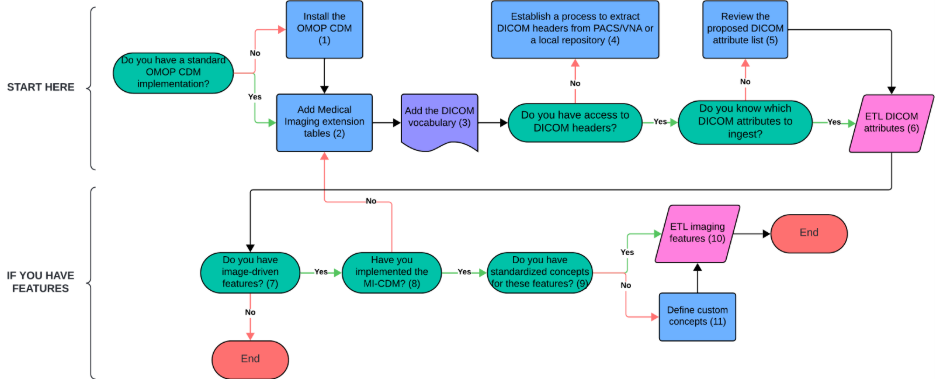

| Section | Wiki step |
|---|---|
| Setup | load the output of notebook 01 |
| 7 | (7) Do you have image-derived features? |
| 8 | (8) Have you implemented the MI-CDM? |
| 9 | (9) Do you have standardized concepts for these features? |
| 11 | (11) Define custom concepts |
| 10 | (10) ETL imaging features |
| Provenance round trip | trace a value back to its image and algorithm |
| Data quality | evaluate completeness, conformance, plausibility, linkage accuracy, and provenance |

The sections follow the order of the wiki flowchart, so step 11 comes before step 10.

**What gets written**:

```
IMAGE_OCCURRENCE ─┐
                   ├─► IMAGE_FEATURE  (what was found, where, by which algorithm)
PERSON ───────────┘  │  image_feature_event_field_concept_id = 1147330 (MEASUREMENT)
                     └─► MEASUREMENT (the value: score, ratio, width in mm)
```

**GPU recommended:** `Runtime → Change runtime type → T4 GPU`. On CPU everything still works; it takes a few minutes longer.

**Before you start:** run notebook 01 to the end. Its section 9 saves the database and the DICOM files to your Google Drive. \
The *Setup* section below loads them.

## Setup — load the output of notebook 01

The cells below load the database and the DICOM files that notebook 01 saved to your Google Drive (`MyDrive/micdm_tutorial/`). \
They go to the same paths that notebook 01 used:

- database: `/content/micdm_tutorial/omop_micdm.db`
- DICOM dir: `/content/micdm_tutorial/dicom`

If notebook 01 has not saved its output, the third cell rebuilds it (download + ETL, about 3 minutes). \
The last cell counts the X-ray images in `IMAGE_OCCURRENCE`.

In [27]:
# Install the packages for DICOM reading and the models
%pip install -q "pydicom>=3.0" pylibjpeg pylibjpeg-libjpeg remotezip torchxrayvision scikit-image

In [28]:
# Copy the database and the DICOM files of notebook 01 from Google Drive
import os, glob, shutil

BASE_DIR = os.environ.get("MICDM_BASE", "/content/micdm_tutorial")
DRIVE_DIR = "/content/drive/MyDrive/micdm_tutorial"      # written by notebook 01, section 9
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not on Colab — Google Drive is not mounted")

if os.path.exists(os.path.join(DRIVE_DIR, "omop_micdm.db")):
    os.makedirs(BASE_DIR, exist_ok=True)
    shutil.copy2(os.path.join(DRIVE_DIR, "omop_micdm.db"), os.path.join(BASE_DIR, "omop_micdm.db"))
    shutil.copytree(os.path.join(DRIVE_DIR, "dicom"), os.path.join(BASE_DIR, "dicom"), dirs_exist_ok=True)
    n_files = len(glob.glob(os.path.join(BASE_DIR, "dicom", "**", "*.dcm"), recursive=True))
    print("database :", os.path.join(BASE_DIR, "omop_micdm.db"))
    print("DICOM dir:", os.path.join(BASE_DIR, "dicom"), f"({n_files} files)")
else:
    print("No notebook 01 output on Google Drive. The next cell rebuilds it.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
database : /content/micdm_tutorial/omop_micdm.db
DICOM dir: /content/micdm_tutorial/dicom (100 files)


In [29]:
#@title Load the shared code of notebook 01 (and rebuild its output if it is missing)
import os, sys, importlib
sys.path.insert(0, os.getcwd())
MICDM_PART1_SRC = r'''"""micdm_part1.py — generated from Notebook 01. Used by the catch-up cells of notebooks 02/03.
Do not edit by hand: regenerate from the notebook builder."""


# Configuration. Re-run this cell after a runtime restart; every later cell relies on it.
import os, re, glob, json, sqlite3, datetime, warnings, urllib.request
import pandas as pd

warnings.filterwarnings("ignore", message="Invalid value for VR")   # RSNA stores PatientAge as a bare integer
pd.set_option("display.max_colwidth", 60)

BASE_DIR = os.environ.get(
    "MICDM_BASE",
    "/content/micdm_tutorial" if os.path.isdir("/content") else os.path.abspath("./micdm_tutorial"))
DB_PATH = os.path.join(BASE_DIR, "omop_micdm.db")
DICOM_DIR = os.path.join(BASE_DIR, "dicom")
VOCAB_DIR = os.path.join(BASE_DIR, "vocab")
for _d in (BASE_DIR, DICOM_DIR, VOCAB_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- tutorial-scale knobs ------------------------------------------------------------
N_IMAGES = int(os.environ.get("MICDM_N_IMAGES", 100))   # keep 50–200 in the session
SUBSET_OFFSET = 0                                          # sorted file list -> same images for everyone
RSNA_ZIP_URL = ("https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/"
                "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip")

# ---- DICOM vocabulary: DICOM2OMOP staging files, pinned to one commit for reproducibility
DICOM2OMOP_COMMIT = "56be2b80c9ba2c9b8f19dc36a8ab5919aed6fb88"
DICOM2OMOP_RAW = ("https://raw.githubusercontent.com/paulnagy/DICOM2OMOP/"
                  f"{DICOM2OMOP_COMMIT}/files/OMOP%20CDM%20Staging/")
VOCAB_FILES = {
    "concept": "omop_table_staging_v5.csv",           # DICOM attributes + CS value sets (2128xxxxxx)
    "maps_to_value": "cs_values_maps_to_value.csv",   # attribute  --Maps to value-->  value
    "maps_to": "cs_values_maps_to.csv",               # value      --Maps to-->        standard (SNOMED)
}
DICOM_CONCEPT_RANGE = (2128000000, 2128999999)

# ---- concepts fixed by OMOP / the ImageWG conventions ---------------------------------
CONCEPT_UNMAPPED = 0
CONCEPT_TYPE_EHR = 32817            # Type Concept 'EHR'
CONCEPT_CHEST_XRAY = 4163872        # SNOMED 399208008 'Plain X-ray of chest' (Procedure)
CONCEPT_MALE, CONCEPT_FEMALE = 8507, 8532
CONCEPT_UNIT_MM = 8588              # UCUM 'mm'

# meas_event_field_concept_id for rows linked to IMAGE_OCCURRENCE. The CDM vocabulary has no
# Field concept for image_occurrence.image_occurrence_id yet, so 0 ('No matching concept') is
# written until the ImageWG designates one. The link itself is measurement_event_id.
FIELD_IMAGE_OCCURRENCE_ID = CONCEPT_UNMAPPED

# ---- DICOM2OMOP attribute-selection rules (transform_imaging_metadata.ipynb) ------------
MEASURABLE_VRS = ["AT", "CS", "DA", "DT", "DS", "FL", "FD", "IS", "SL", "SS", "SV", "TM", "UL", "US", "UV"]
NUMERIC_VRS = ["DS", "FL", "FD", "IS", "SL", "SS", "SV", "UL", "US", "UV"]
ALWAYS_INCLUDE_TAGS = ["00080070"]       # Manufacturer (LO), kept by DICOM2OMOP for analysis
MAX_VALUE_LEN = 50
# ETL guide §4: attributes that populate IMAGE_OCCURRENCE (not repeated in MEASUREMENT)
CORE_TAGS = {"00080020": "Study Date", "00100020": "Patient ID", "00080060": "Modality",
             "00180015": "Body Part Examined", "0020000D": "Study Instance UID",
             "0020000E": "Series Instance UID"}
UNIT_BY_TAG = {"00280030": CONCEPT_UNIT_MM,   # Pixel Spacing
               "00181164": CONCEPT_UNIT_MM,   # Imager Pixel Spacing
               "00180050": CONCEPT_UNIT_MM,   # Slice Thickness
               "00181110": CONCEPT_UNIT_MM,   # Distance Source to Detector
               "00181111": CONCEPT_UNIT_MM}   # Distance Source to Patient


def connect(db_path=None):
    conn = sqlite3.connect(db_path or DB_PATH)
    conn.execute("PRAGMA foreign_keys = ON")
    return conn


def q(sql, params=()):
    """Run a read-only query and return a DataFrame."""
    with connect() as conn:
        return pd.read_sql_query(sql, conn, params=params)


CDM_DDL = """
CREATE TABLE IF NOT EXISTS concept (
    concept_id        INTEGER NOT NULL PRIMARY KEY,
    concept_name      VARCHAR(255) NOT NULL,
    domain_id         VARCHAR(20)  NOT NULL,
    vocabulary_id     VARCHAR(20)  NOT NULL,
    concept_class_id  VARCHAR(20)  NOT NULL,
    standard_concept  VARCHAR(1),
    concept_code      VARCHAR(50)  NOT NULL,
    valid_start_date  DATE NOT NULL,
    valid_end_date    DATE NOT NULL,
    invalid_reason    VARCHAR(1));

CREATE TABLE IF NOT EXISTS concept_relationship (
    concept_id_1      INTEGER NOT NULL,
    concept_id_2      INTEGER NOT NULL,
    relationship_id   VARCHAR(20) NOT NULL,
    valid_start_date  DATE NOT NULL,
    valid_end_date    DATE NOT NULL,
    invalid_reason    VARCHAR(1),
    PRIMARY KEY (concept_id_1, concept_id_2, relationship_id));

CREATE TABLE IF NOT EXISTS person (
    person_id                   INTEGER NOT NULL PRIMARY KEY,
    gender_concept_id           INTEGER NOT NULL,
    year_of_birth               INTEGER NOT NULL,
    month_of_birth              INTEGER,
    day_of_birth                INTEGER,
    birth_datetime              TIMESTAMP,
    race_concept_id             INTEGER NOT NULL,
    ethnicity_concept_id        INTEGER NOT NULL,
    location_id                 INTEGER,
    provider_id                 INTEGER,
    care_site_id                INTEGER,
    person_source_value         VARCHAR(50),
    gender_source_value         VARCHAR(50),
    gender_source_concept_id    INTEGER,
    race_source_value           VARCHAR(50),
    race_source_concept_id      INTEGER,
    ethnicity_source_value      VARCHAR(50),
    ethnicity_source_concept_id INTEGER);

CREATE TABLE IF NOT EXISTS observation_period (
    observation_period_id         INTEGER NOT NULL PRIMARY KEY,
    person_id                     INTEGER NOT NULL REFERENCES person (person_id),
    observation_period_start_date DATE NOT NULL,
    observation_period_end_date   DATE NOT NULL,
    period_type_concept_id        INTEGER NOT NULL);

CREATE TABLE IF NOT EXISTS procedure_occurrence (
    procedure_occurrence_id     INTEGER NOT NULL PRIMARY KEY,
    person_id                   INTEGER NOT NULL REFERENCES person (person_id),
    procedure_concept_id        INTEGER NOT NULL,
    procedure_date              DATE NOT NULL,
    procedure_datetime          TIMESTAMP,
    procedure_end_date          DATE,
    procedure_end_datetime      TIMESTAMP,
    procedure_type_concept_id   INTEGER NOT NULL,
    modifier_concept_id         INTEGER,
    quantity                    INTEGER,
    provider_id                 INTEGER,
    visit_occurrence_id         INTEGER,
    visit_detail_id             INTEGER,
    procedure_source_value      VARCHAR(50),
    procedure_source_concept_id INTEGER,
    modifier_source_value       VARCHAR(50));

CREATE TABLE IF NOT EXISTS measurement (
    measurement_id                INTEGER NOT NULL PRIMARY KEY,
    person_id                     INTEGER NOT NULL REFERENCES person (person_id),
    measurement_concept_id        INTEGER NOT NULL,
    measurement_date              DATE NOT NULL,
    measurement_datetime          TIMESTAMP,
    measurement_time              VARCHAR(10),
    measurement_type_concept_id   INTEGER NOT NULL,
    operator_concept_id           INTEGER,
    value_as_number               NUMERIC,
    value_as_concept_id           INTEGER,
    unit_concept_id               INTEGER,
    range_low                     NUMERIC,
    range_high                    NUMERIC,
    provider_id                   INTEGER,
    visit_occurrence_id           INTEGER,
    visit_detail_id               INTEGER,
    measurement_source_value      VARCHAR(50),
    measurement_source_concept_id INTEGER,
    unit_source_value             VARCHAR(50),
    unit_source_concept_id        INTEGER,
    value_source_value            VARCHAR(50),
    measurement_event_id          INTEGER,
    meas_event_field_concept_id   INTEGER);
CREATE INDEX IF NOT EXISTS idx_measurement_event ON measurement (measurement_event_id, meas_event_field_concept_id);
CREATE INDEX IF NOT EXISTS idx_measurement_concept ON measurement (measurement_concept_id);
"""


def create_cdm_tables(conn):
    conn.executescript(CDM_DDL)


MICDM_DDL = """
CREATE TABLE IF NOT EXISTS image_occurrence (
    image_occurrence_id       INTEGER NOT NULL PRIMARY KEY,
    person_id                 INTEGER NOT NULL REFERENCES person (person_id),
    procedure_occurrence_id   INTEGER NOT NULL REFERENCES procedure_occurrence (procedure_occurrence_id),
    visit_occurrence_id       INTEGER,
    anatomic_site_concept_id  INTEGER,
    wadors_uri                VARCHAR(10000),
    local_path                VARCHAR(10000),
    image_occurrence_date     DATE NOT NULL,
    image_study_uid           VARCHAR(10000) NOT NULL,
    image_series_uid          VARCHAR(10000) NOT NULL,
    modality_concept_id       INTEGER NOT NULL);

CREATE TABLE IF NOT EXISTS image_feature (
    image_feature_id                      INTEGER NOT NULL PRIMARY KEY,
    person_id                             INTEGER NOT NULL REFERENCES person (person_id),
    image_occurrence_id                   INTEGER NOT NULL REFERENCES image_occurrence (image_occurrence_id),
    image_feature_event_field_concept_id  INTEGER,
    image_feature_event_id                INTEGER,
    image_feature_concept_id              INTEGER NOT NULL,
    image_feature_type_concept_id         INTEGER NOT NULL,
    image_finding_concept_id              INTEGER,
    image_finding_id                      INTEGER,
    anatomic_site_concept_id              INTEGER,
    alg_system                            VARCHAR(10000),
    alg_datetime                          TIMESTAMP);
CREATE UNIQUE INDEX IF NOT EXISTS idx_image_occurrence_series ON image_occurrence (image_study_uid, image_series_uid);
CREATE INDEX IF NOT EXISTS idx_image_feature_image ON image_feature (image_occurrence_id);
"""

# Tables written by the ETL, parent -> child. Re-running a step clears that table and
# everything downstream of it, so foreign keys never dangle.
ETL_TABLE_ORDER = ["person", "observation_period", "procedure_occurrence",
                   "image_occurrence", "measurement", "image_feature"]


def create_micdm_tables(conn):
    conn.executescript(MICDM_DDL)


def clear_from(conn, table):
    """Delete `table` and every ETL table downstream of it (children first)."""
    downstream = ETL_TABLE_ORDER[ETL_TABLE_ORDER.index(table):]
    for t in reversed(downstream):
        if t == "observation_period" and table not in ("person", "observation_period"):
            continue                                   # not a child of procedure/image tables
        conn.execute(f"DELETE FROM {t}")
    return downstream


# Standard concepts the tutorial refers to. This is a *display subset* so queries can show
# names — it is not a substitute for loading the Athena vocabularies at your site.
STANDARD_CONCEPTS = [
    # concept_id, name, domain, vocabulary, class, standard, code
    (0, "No matching concept", "Metadata", "None", "Undefined", None, "No matching concept"),
    (8507, "MALE", "Gender", "Gender", "Gender", "S", "M"),
    (8532, "FEMALE", "Gender", "Gender", "Gender", "S", "F"),
    (32817, "EHR", "Type Concept", "Type Concept", "Type Concept", "S", "OMOP4976890"),
    (4163872, "Plain X-ray of chest", "Procedure", "SNOMED", "Procedure", "S", "399208008"),
    (4184181, "Thoracic cavity structure", "Spec Anatomic Site", "SNOMED", "Body Structure", "S", "43799004"),
    (4213162, "Lung structure", "Spec Anatomic Site", "SNOMED", "Body Structure", "S", "39607008"),
    (8588, "millimeter", "Unit", "UCUM", "Unit", "S", "mm"),
]


def download_vocabulary(vocab_dir=None):
    vocab_dir = vocab_dir or VOCAB_DIR
    paths = {}
    for key, fname in VOCAB_FILES.items():
        dest = os.path.join(vocab_dir, fname)
        if not os.path.exists(dest):
            urllib.request.urlretrieve(DICOM2OMOP_RAW + fname, dest)
        paths[key] = dest
    return paths


def _yyyymmdd_to_iso(s):
    s = str(s)
    return f"{s[:4]}-{s[4:6]}-{s[6:8]}" if len(s) == 8 and s.isdigit() else s


def insert_concepts(conn, rows):
    conn.executemany(
        """INSERT OR REPLACE INTO concept (concept_id, concept_name, domain_id, vocabulary_id,
               concept_class_id, standard_concept, concept_code, valid_start_date,
               valid_end_date, invalid_reason)
           VALUES (?,?,?,?,?,?,?,'1970-01-01','2099-12-31',NULL)""", rows)


def load_dicom_vocabulary(conn, paths):
    concept = pd.read_csv(paths["concept"], dtype=str)
    concept = concept.where(concept.notna(), None)
    concept["valid_start_date"] = concept["valid_start_date"].map(_yyyymmdd_to_iso)
    concept["valid_end_date"] = concept["valid_end_date"].map(_yyyymmdd_to_iso)
    cols = ["concept_id", "concept_name", "domain_id", "vocabulary_id", "concept_class_id",
            "standard_concept", "concept_code", "valid_start_date", "valid_end_date", "invalid_reason"]
    conn.executemany(f"INSERT OR REPLACE INTO concept ({', '.join(cols)}) VALUES ({', '.join('?' * len(cols))})",
                     concept[cols].itertuples(index=False, name=None))

    rel = pd.concat([pd.read_csv(paths["maps_to_value"]), pd.read_csv(paths["maps_to"])])
    conn.execute("DELETE FROM concept_relationship WHERE concept_id_1 BETWEEN ? AND ?", DICOM_CONCEPT_RANGE)
    conn.executemany(
        """INSERT OR REPLACE INTO concept_relationship
           (concept_id_1, concept_id_2, relationship_id, valid_start_date, valid_end_date, invalid_reason)
           VALUES (?,?,?,'1970-01-01','2099-12-31',NULL)""",
        rel[["concept_id_1", "concept_id_2", "relationship_id"]].itertuples(index=False, name=None))
    insert_concepts(conn, STANDARD_CONCEPTS)
    return len(concept), len(rel)


def download_rsna_subset(dest=None, n_images=None, offset=None, url=RSNA_ZIP_URL):
    """Pull n_images .dcm members out of the remote ZIP. Skips the download if enough files exist."""
    dest, n_images = dest or DICOM_DIR, n_images or N_IMAGES
    offset = SUBSET_OFFSET if offset is None else offset
    existing = sorted(glob.glob(os.path.join(dest, "**", "*.dcm"), recursive=True))
    if len(existing) >= n_images:
        print(f"{len(existing)} DICOM files already present — download skipped")
        return existing[:n_images] if len(existing) == n_images else existing
    from remotezip import RemoteZip
    with RemoteZip(url) as z:
        names = sorted(n for n in z.namelist() if n.lower().endswith(".dcm"))
        print(f"archive holds {len(names):,} DICOM files; taking [{offset}:{offset + n_images}]")
        for i, name in enumerate(names[offset:offset + n_images], 1):
            if not os.path.exists(os.path.join(dest, name)):
                z.extract(name, dest)
            if i % 25 == 0:
                print(f"  {i}/{n_images}")
    return sorted(glob.glob(os.path.join(dest, "**", "*.dcm"), recursive=True))


def index_dicom_archive(dicom_dir=None):
    import pydicom
    rows = []
    for path in sorted(glob.glob(os.path.join(dicom_dir or DICOM_DIR, "**", "*.dcm"), recursive=True)):
        ds = pydicom.dcmread(path, stop_before_pixels=True,
                             specific_tags=["PatientID", "StudyInstanceUID", "SeriesInstanceUID",
                                            "SOPInstanceUID", "Modality"])
        rows.append({"local_path": os.path.abspath(path),
                     "patient_id": str(ds.get("PatientID", "")),
                     "study_uid": str(ds.get("StudyInstanceUID", "")),
                     "series_uid": str(ds.get("SeriesInstanceUID", "")),
                     "sop_uid": str(ds.get("SOPInstanceUID", "")),
                     "modality": str(ds.get("Modality", "")),
                     "file_bytes": os.path.getsize(path)})
    return pd.DataFrame(rows)


SKIP_VRS = {"SQ", "OB", "OW", "OF", "OD", "OL", "OV", "UN", "DT"}

def flatten_header(ds):
    """Top-level DICOM elements -> list of (Tag, keyword, vr, vm, Value)."""
    out = []
    for elem in ds:
        if elem.VR in SKIP_VRS or elem.tag == 0x7FE00010:
            continue
        v = elem.value
        if v is None or v == "":
            value = None
        elif elem.VM > 1:
            value = ", ".join(str(x) for x in v)
        else:
            value = str(v)
        out.append((f"{elem.tag.group:04X}{elem.tag.element:04X}", elem.keyword, elem.VR, elem.VM, value))
    return out


def extract_series_metadata(inventory):
    import pydicom
    first = inventory.sort_values("local_path").groupby(["study_uid", "series_uid"], as_index=False).first()
    rows = []
    for rec in first.itertuples(index=False):
        ds = pydicom.dcmread(rec.local_path, stop_before_pixels=True)
        for tag, keyword, vr, vm, value in flatten_header(ds):
            rows.append((rec.study_uid, rec.series_uid, tag, keyword, vr, vm, value))
    return pd.DataFrame(rows, columns=["StudyUID", "SeriesUID", "Tag", "keyword", "vr", "vm", "Value"])


def map_tags_to_concepts(flat_df, conn):
    attrs = pd.read_sql_query(
        """SELECT concept_id, concept_code, concept_name FROM concept
           WHERE vocabulary_id = 'DICOM' AND concept_class_id = 'DICOM Attributes'""", conn)
    m = flat_df.merge(attrs, how="left", left_on="Tag", right_on="concept_code")
    m["concept_id"] = m["concept_id"].astype("Int64")
    return m


def select_attributes(metadata_omop):
    structured = metadata_omop["vr"].isin(MEASURABLE_VRS)
    too_long = metadata_omop["Value"].fillna("").str.len() > MAX_VALUE_LEN
    exclude = metadata_omop.loc[metadata_omop["concept_id"].notna() & structured & too_long, "Tag"].unique()
    keep = (metadata_omop["concept_id"].notna()
            & metadata_omop["Value"].notna()
            & ~metadata_omop["Tag"].isin(exclude)
            & (structured | metadata_omop["Tag"].isin(ALWAYS_INCLUDE_TAGS))
            & ~metadata_omop["Tag"].isin(list(CORE_TAGS)))
    return metadata_omop[keep].copy()


def dicom_age_years(raw):
    """DICOM AS ('051Y', '006M') or RSNA's bare integer -> years (float) or None."""
    m = re.match(r"^\s*(\d+)\s*([DWMY])?\s*$", str(raw or ""), re.IGNORECASE)
    if not m:
        return None
    n, unit = int(m.group(1)), (m.group(2) or "Y").upper()
    return {"Y": n, "M": n / 12, "W": n / 52.18, "D": n / 365.25}[unit]


def dicom_date_iso(raw):
    s = str(raw or "").strip()
    return f"{s[:4]}-{s[4:6]}-{s[6:8]}" if len(s) == 8 and s.isdigit() else None


def series_wide(conn, tags):
    """Pivot selected tags of stg_dicom_metadata_long to one row per series (DICOM2OMOP cell 23)."""
    long = pd.read_sql_query("SELECT StudyUID, SeriesUID, Tag, Value FROM stg_dicom_metadata_long", conn)
    wide = (long[long["Tag"].isin(tags)]
            .pivot(index=["StudyUID", "SeriesUID"], columns="Tag", values="Value").reset_index())
    wide.columns.name = None
    for t in tags:
        if t not in wide:
            wide[t] = None
    return wide


def etl_person(conn):
    clear_from(conn, "person")
    w = series_wide(conn, ["00100020", "00100040", "00101010", "00080020"])
    w = w.sort_values(["00100020", "00080020"])
    pts = w.groupby("00100020", as_index=False).first()          # first study per patient
    pts["person_id"] = range(1, len(pts) + 1)
    pts["gender_concept_id"] = pts["00100040"].str.upper().map(
        {"M": CONCEPT_MALE, "F": CONCEPT_FEMALE}).fillna(CONCEPT_UNMAPPED).astype(int)
    study_year = pts["00080020"].map(dicom_date_iso).str[:4].astype(float).fillna(1900)
    age = pts["00101010"].map(dicom_age_years)
    pts["year_of_birth"] = (study_year - age.fillna(0)).astype(int)

    conn.executemany(
        """INSERT INTO person (person_id, gender_concept_id, year_of_birth, race_concept_id,
               ethnicity_concept_id, gender_source_value) VALUES (?,?,?,0,0,?)""",
        pts[["person_id", "gender_concept_id", "year_of_birth", "00100040"]].itertuples(index=False, name=None))

    conn.execute("DROP TABLE IF EXISTS registry_idmap")
    conn.execute("CREATE TABLE registry_idmap (source_id VARCHAR(250) NOT NULL, person_id INTEGER NOT NULL, source_name VARCHAR(250))")
    conn.executemany("INSERT INTO registry_idmap VALUES (?,?,'RSNA DICOM PatientID')",
                     pts[["00100020", "person_id"]].itertuples(index=False, name=None))

    # observation period = span of imaging (the only data we have for these persons)
    conn.execute("""
        INSERT INTO observation_period (observation_period_id, person_id, observation_period_start_date,
                                        observation_period_end_date, period_type_concept_id)
        SELECT r.person_id, r.person_id, MIN(d.study_date), MAX(d.study_date), ?
        FROM registry_idmap r
        JOIN (SELECT l1.Value AS patient_id,
                     substr(l2.Value,1,4)||'-'||substr(l2.Value,5,2)||'-'||substr(l2.Value,7,2) AS study_date
              FROM stg_dicom_metadata_long l1
              JOIN stg_dicom_metadata_long l2 ON l2.SeriesUID = l1.SeriesUID AND l2.Tag = '00080020'
              WHERE l1.Tag = '00100020') d ON d.patient_id = r.source_id
        GROUP BY r.person_id""", (CONCEPT_TYPE_EHR,))
    return len(pts)


def etl_procedure_occurrence(conn):
    clear_from(conn, "procedure_occurrence")
    w = series_wide(conn, ["00100020", "00080020", "00080060", "00180015"])
    st = w.sort_values("SeriesUID").groupby("StudyUID", as_index=False).first().sort_values("StudyUID")
    ids = pd.read_sql_query("SELECT source_id, person_id FROM registry_idmap", conn)
    st = st.merge(ids, left_on="00100020", right_on="source_id", how="left")
    st["procedure_occurrence_id"] = range(1, len(st) + 1)
    is_cxr = st["00080060"].isin(["CR", "DX"]) & st["00180015"].str.upper().isin(["CHEST", "THORAX"])
    st["procedure_concept_id"] = is_cxr.map({True: CONCEPT_CHEST_XRAY, False: CONCEPT_UNMAPPED})
    st["procedure_date"] = st["00080020"].map(dicom_date_iso)
    st["procedure_source_value"] = (st["00080060"].fillna("") + " " + st["00180015"].fillna("")).str.strip()
    conn.executemany(
        """INSERT INTO procedure_occurrence (procedure_occurrence_id, person_id, procedure_concept_id,
               procedure_date, procedure_type_concept_id, procedure_source_value)
           VALUES (?,?,?,?,?,?)""",
        [(r.procedure_occurrence_id, r.person_id, r.procedure_concept_id, r.procedure_date,
          CONCEPT_TYPE_EHR, r.procedure_source_value) for r in st.itertuples()])
    st[["StudyUID", "procedure_occurrence_id"]].rename(columns={"StudyUID": "study_uid"}).to_sql(
        "stg_study_procedure", conn, if_exists="replace", index=False)
    if (~is_cxr).any():
        print(f"  ! {(~is_cxr).sum()} studies are not chest radiographs -> procedure_concept_id = 0")
    return len(st)


def value_concept_lookup(conn):
    """{(attribute_concept_id, value_code): value_concept_id} via 'Maps to value'."""
    df = pd.read_sql_query(
        """SELECT r.concept_id_1 AS attr_id, v.concept_code AS code, v.concept_id AS value_id
           FROM concept_relationship r JOIN concept v ON v.concept_id = r.concept_id_2
           WHERE r.relationship_id = 'Maps to value'""", conn)
    return {(int(a), str(c).upper()): int(v) for a, c, v in df.itertuples(index=False)}


def maps_to_lookup(conn):
    df = pd.read_sql_query("SELECT concept_id_1, concept_id_2 FROM concept_relationship WHERE relationship_id = 'Maps to'", conn)
    return dict(zip(df.concept_id_1.astype(int), df.concept_id_2.astype(int)))


def attribute_id(conn, tag):
    return int(conn.execute("SELECT concept_id FROM concept WHERE vocabulary_id='DICOM' AND concept_code=?", (tag,)).fetchone()[0])


def normalize_body_part(raw):
    return re.sub(r"[^A-Z]", "", str(raw or "").upper())


def etl_image_occurrence(conn):
    clear_from(conn, "image_occurrence")
    vmap, mapsto = value_concept_lookup(conn), maps_to_lookup(conn)
    attr_modality, attr_bodypart = attribute_id(conn, "00080060"), attribute_id(conn, "00180015")

    w = series_wide(conn, ["00100020", "00080020", "00080060", "00180015"]).sort_values(["StudyUID", "SeriesUID"])
    ids = pd.read_sql_query("SELECT source_id, person_id FROM registry_idmap", conn)
    proc = pd.read_sql_query("SELECT study_uid, procedure_occurrence_id FROM stg_study_procedure", conn)
    path = pd.read_sql_query(
        "SELECT series_uid, MIN(local_path) AS local_path FROM stg_dicom_inventory GROUP BY series_uid", conn)
    w = (w.merge(ids, left_on="00100020", right_on="source_id", how="left")
          .merge(proc, left_on="StudyUID", right_on="study_uid", how="left")
          .merge(path, left_on="SeriesUID", right_on="series_uid", how="left"))

    w["image_occurrence_id"] = range(1, len(w) + 1)
    w["modality_concept_id"] = [vmap.get((attr_modality, str(m).upper()), CONCEPT_UNMAPPED) for m in w["00080060"]]
    bp_value = [vmap.get((attr_bodypart, normalize_body_part(b))) for b in w["00180015"]]
    w["anatomic_site_concept_id"] = [mapsto.get(v, CONCEPT_UNMAPPED) if v else CONCEPT_UNMAPPED for v in bp_value]
    w["image_occurrence_date"] = w["00080020"].map(dicom_date_iso)

    conn.executemany(
        """INSERT INTO image_occurrence (image_occurrence_id, person_id, procedure_occurrence_id,
               visit_occurrence_id, anatomic_site_concept_id, wadors_uri, local_path,
               image_occurrence_date, image_study_uid, image_series_uid, modality_concept_id)
           VALUES (?,?,?,NULL,?,NULL,?,?,?,?,?)""",
        [(r.image_occurrence_id, r.person_id, r.procedure_occurrence_id, r.anatomic_site_concept_id,
          r.local_path, r.image_occurrence_date, r.StudyUID, r.SeriesUID, r.modality_concept_id)
         for r in w.itertuples()])
    unmapped = w.loc[w["modality_concept_id"] == 0, "00080060"].unique().tolist()
    if unmapped:
        print("  ! unmapped Modality values:", unmapped)
    return len(w)


def to_number(s):
    try:
        return float(s)
    except (TypeError, ValueError):
        return None


def etl_dicom_measurements(conn, selected):
    clear_from(conn, "measurement")
    io = pd.read_sql_query("SELECT image_occurrence_id, person_id, image_series_uid, image_occurrence_date FROM image_occurrence", conn)
    df = selected.merge(io, left_on="SeriesUID", right_on="image_series_uid", how="inner")

    # split multi-valued elements: one row per value (ETL guide §5.2)
    df["component"] = [v.split(", ") if vm > 1 else [v] for v, vm in zip(df["Value"], df["vm"])]
    df = df.explode("component").reset_index(drop=True)

    vmap = value_concept_lookup(conn)

    rows, mid = [], 1
    for r in df.itertuples():
        attr = int(r.concept_id)
        num = to_number(r.component) if r.vr in NUMERIC_VRS else None
        val_concept = vmap.get((attr, str(r.component).upper()), CONCEPT_UNMAPPED) if r.vr == "CS" else None
        rows.append((mid, int(r.person_id), attr, r.image_occurrence_date, CONCEPT_TYPE_EHR, num, val_concept,
                     UNIT_BY_TAG.get(r.Tag) if num is not None else None,
                     str(r.Value)[:50], attr, str(r.component)[:50],
                     int(r.image_occurrence_id), FIELD_IMAGE_OCCURRENCE_ID))
        mid += 1
    conn.executemany(
        """INSERT INTO measurement (measurement_id, person_id, measurement_concept_id, measurement_date,
               measurement_type_concept_id, value_as_number, value_as_concept_id, unit_concept_id,
               measurement_source_value, measurement_source_concept_id, value_source_value,
               measurement_event_id, meas_event_field_concept_id)
           VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)""", rows)
    return len(rows)


DQ_CHECKS_PART1 = [
    # (category, check, SQL returning the number of violating rows)
    ("completeness", "image_occurrence without person / procedure",
     "SELECT COUNT(*) FROM image_occurrence WHERE person_id IS NULL OR procedure_occurrence_id IS NULL"),
    ("completeness", "image_occurrence missing study/series UID or date",
     "SELECT COUNT(*) FROM image_occurrence WHERE image_study_uid IS NULL OR image_series_uid IS NULL OR image_occurrence_date IS NULL"),
    ("completeness", "image_occurrence with modality_concept_id = 0",
     "SELECT COUNT(*) FROM image_occurrence WHERE modality_concept_id = 0"),
    ("completeness", "image_occurrence without wadors_uri AND local_path",
     "SELECT COUNT(*) FROM image_occurrence WHERE wadors_uri IS NULL AND local_path IS NULL"),
    ("completeness", "DICOM measurement without measurement_event_id",
     "SELECT COUNT(*) FROM measurement WHERE measurement_type_concept_id = 32817 AND measurement_event_id IS NULL"),
    ("conformance", "concept_ids not present in CONCEPT (image_occurrence)",
     """SELECT COUNT(*) FROM image_occurrence io LEFT JOIN concept c ON c.concept_id = io.modality_concept_id
        LEFT JOIN concept a ON a.concept_id = io.anatomic_site_concept_id
        WHERE c.concept_id IS NULL OR (io.anatomic_site_concept_id IS NOT NULL AND a.concept_id IS NULL)"""),
    ("conformance", "measurement_concept_id not a DICOM attribute (DICOM rows)",
     """SELECT COUNT(*) FROM measurement m LEFT JOIN concept c ON c.concept_id = m.measurement_concept_id
        WHERE m.measurement_type_concept_id = 32817 AND (c.concept_class_id IS NULL OR c.concept_class_id <> 'DICOM Attributes')"""),
    ("conformance", "measurement without source value",
     "SELECT COUNT(*) FROM measurement WHERE measurement_source_value IS NULL"),
    ("conformance", "CS value stored as number / numeric VR stored as concept",
     """SELECT COUNT(*) FROM measurement WHERE value_as_number IS NOT NULL AND value_as_concept_id IS NOT NULL"""),
    ("conformance", "duplicate (study_uid, series_uid)",
     "SELECT COUNT(*) FROM (SELECT 1 FROM image_occurrence GROUP BY image_study_uid, image_series_uid HAVING COUNT(*) > 1)"),
    ("plausibility", "Pixel Spacing outside 0.05–1.0 mm",
     """SELECT COUNT(*) FROM measurement m JOIN concept c ON c.concept_id = m.measurement_concept_id
        WHERE c.concept_code = '00280030' AND (m.value_as_number < 0.05 OR m.value_as_number > 1.0)"""),
    ("plausibility", "Rows/Columns outside 256–5000 px",
     """SELECT COUNT(*) FROM measurement m JOIN concept c ON c.concept_id = m.measurement_concept_id
        WHERE c.concept_code IN ('00280010','00280011') AND (m.value_as_number < 256 OR m.value_as_number > 5000)"""),
    ("linkage", "measurement_event_id not resolving to image_occurrence",
     """SELECT COUNT(*) FROM measurement m LEFT JOIN image_occurrence io ON io.image_occurrence_id = m.measurement_event_id
        WHERE m.measurement_event_id IS NOT NULL AND io.image_occurrence_id IS NULL"""),
    ("linkage", "measurement.person_id differs from its image's person_id",
     """SELECT COUNT(*) FROM measurement m JOIN image_occurrence io ON io.image_occurrence_id = m.measurement_event_id
        WHERE m.person_id <> io.person_id"""),
    ("linkage", "image person differs from its procedure's person",
     """SELECT COUNT(*) FROM image_occurrence io JOIN procedure_occurrence po USING (procedure_occurrence_id)
        WHERE io.person_id <> po.person_id"""),
]


def run_dq(checks):
    with connect() as conn:
        res = [(cat, name, conn.execute(sql).fetchone()[0]) for cat, name, sql in checks]
        fk = len(conn.execute("PRAGMA foreign_key_check").fetchall())
    res.append(("linkage", "PRAGMA foreign_key_check", fk))
    out = pd.DataFrame(res, columns=["category", "check", "violations"])
    out["status"] = out["violations"].map(lambda n: "PASS" if n == 0 else "REVIEW")
    return out


def build_part1(verbose=True):
    """Run notebook 01 end to end (catch-up)."""
    with connect() as conn:
        create_cdm_tables(conn)
        create_micdm_tables(conn)
        load_dicom_vocabulary(conn, download_vocabulary())
    download_rsna_subset()
    inv = index_dicom_archive()
    flat = extract_series_metadata(inv)
    with connect() as conn:
        inv.to_sql("stg_dicom_inventory", conn, if_exists="replace", index=False)
        flat.to_sql("stg_dicom_metadata_long", conn, if_exists="replace", index=False)
        selected = select_attributes(map_tags_to_concepts(flat, conn))
        etl_person(conn)
        etl_procedure_occurrence(conn)
        etl_image_occurrence(conn)
        n = etl_dicom_measurements(conn, selected)
    if verbose:
        print(f"notebook 01 rebuilt: {len(inv)} files, {flat.SeriesUID.nunique()} series, {n} DICOM measurements")
'''
open("micdm_part1.py", "w").write(MICDM_PART1_SRC)
import micdm_part1; importlib.reload(micdm_part1)
from micdm_part1 import *

def _ready():
    try:
        return os.path.exists(DB_PATH) and q("""SELECT COUNT(*) FROM measurement WHERE measurement_type_concept_id = 32817""").iloc[0, 0] > 0
    except Exception:
        return False

if _ready():
    print("Earlier notebook output found:", DB_PATH)
else:
    print("Rebuilding earlier notebook output (notebook 01: download + ETL, ~3 min) ...")
    build_part1()

Earlier notebook output found: /content/micdm_tutorial/omop_micdm.db


**Check the records**

*Custom concepts* (2-billion range, non-standard)

| DICOM value (Modality) | Concept name | Custom concept_id | Source |
|---|---|---|---|
| CR | Computed radiography | 2128009189 | [staging v5](https://github.com/paulnagy/DICOM2OMOP/blob/56be2b80c9ba2c9b8f19dc36a8ab5919aed6fb88/files/OMOP%20CDM%20Staging/omop_table_staging_v5.csv) — DICOM Value Sets |
| DX | Digital radiography | 2128009197 | [staging v5](https://github.com/paulnagy/DICOM2OMOP/blob/56be2b80c9ba2c9b8f19dc36a8ab5919aed6fb88/files/OMOP%20CDM%20Staging/omop_table_staging_v5.csv) — DICOM Value Sets |

In [30]:
# Count the X-ray images in IMAGE_OCCURRENCE by modality
q("""
SELECT io.modality_concept_id, c.concept_name AS modality, c.concept_code AS dicom_value,
       COUNT(*) AS images, SUM(io.local_path IS NOT NULL) AS with_local_path,
       COUNT(DISTINCT io.person_id) AS persons
FROM image_occurrence io
LEFT JOIN concept c ON c.concept_id = io.modality_concept_id
WHERE io.modality_concept_id IN (2128009189, 2128009197)     -- CR, DX: X-ray modalities
GROUP BY io.modality_concept_id, c.concept_name, c.concept_code
""")

,modality_concept_id,modality,dicom_value,images,with_local_path,persons
0,2128009189,Computed radiography,CR,100,100,100


## 7. Wiki step 7 — do you have image-derived features?

Read the images listed in `IMAGE_OCCURRENCE` (`local_path`), then run the classifier (7b) and the segmenter (7c).
The *Provenance round trip* section comes back to the results and shows example images.



### The algorithm

| | |
|---|---|
| Library | [TorchXRayVision](https://github.com/mlmed/torchxrayvision) (Apache-2.0) — Cohen JP *et al.*, MIDL 2022 |
| Classifier | `DenseNet(weights="densenet121-res224-all")` — 18 findings, ~28 MB |
| Segmenter | `PSPNet()` (ChestX-Det) — 14 anatomical masks, ~270 MB; gives heart and lung geometry |

- TorchXRayVision produces both kinds of output:
  - **coded findings** (classifier)
  - **quantitative features** (segmentation)
- It **calibrates** each classifier output so that the published operating point sits at 0.5. The stored value is that **calibrated score**.

### How the algorithm runs

Steps: read `IMAGE_OCCURRENCE.local_path` → decode pixels → model. \
Preprocess:
1. decode
2. invert if `MONOCHROME1`
3. scale to [-1024, 1024] using `BitsStored`
4. centre-crop and resize (224 for the classifier, 512 for the segmenter).

### 7a. Settings and shared functions

In [31]:
# Set the model settings and choose CPU or GPU
import sys, time, uuid, hashlib, platform
import numpy as np

BATCH_SIZE = 8                     # lower to 2 if a GPU runs out of memory
RUN_SEGMENTATION = True            # False skips the 270 MB segmentation model
CLS_WEIGHTS = "densenet121-res224-all"
CLS_INPUT_SIZE, SEG_INPUT_SIZE = 224, 512
SEG_MASK_THRESHOLD = 0.5
CLS_LABELS = ["Lung Opacity", "Enlarged Cardiomediastinum", "Consolidation"]   # classifier outputs to keep


def device():
    import torch
    return "cuda" if torch.cuda.is_available() else "cpu"
# ▶ run
print("device:", device(), "| batch size:", BATCH_SIZE, "| segmentation:", RUN_SEGMENTATION)

device: cuda | batch size: 8 | segmentation: True


In [32]:
# Define the image reading and provenance functions
PREPROCESSING = ("pydicom pixel_array; invert if MONOCHROME1; xrv.datasets.normalize(arr, 2**BitsStored-1); "
                 "XRayCenterCrop; XRayResizer(size, engine='skimage')")


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def read_cxr(path):
    import pydicom, torchxrayvision as xrv
    ds = pydicom.dcmread(path)
    arr = ds.pixel_array.astype(np.float32)
    if str(ds.get("PhotometricInterpretation", "")).upper() == "MONOCHROME1":
        arr = arr.max() - arr
    if arr.ndim == 3:
        arr = arr.mean(axis=2)
    bits = int(ds.get("BitsStored", 0) or 0)
    maxval = max(float(2 ** bits - 1) if bits else float(arr.max()), float(arr.max()))
    img = xrv.datasets.normalize(arr, maxval)[None, ...]
    sp = ds.get("PixelSpacing")
    meta = {"rows": arr.shape[0], "columns": arr.shape[1],
            "spacing": (float(sp[0]), float(sp[1])) if sp else None}
    return img, meta


def model_input(img, size):
    import torchxrayvision as xrv
    img = xrv.datasets.XRayCenterCrop()(img)
    return xrv.datasets.XRayResizer(size, engine="skimage")(img).astype(np.float32)


def image_rows():
    return q("""SELECT image_occurrence_id, person_id, image_occurrence_date, local_path
                FROM image_occurrence WHERE local_path IS NOT NULL ORDER BY image_occurrence_id""")


def run_record(task, model, model_name, version, hyper):
    import torch, torchxrayvision as xrv
    wfile = getattr(model, "weights_filename_local", None)
    sha = sha256_file(wfile) if wfile and os.path.exists(wfile) else None
    rec = {"run_uuid": str(uuid.uuid4()), "task": task, "model_name": model_name, "model_version": version,
           "library": f"torchxrayvision {xrv.__version__}", "weights_sha256": sha,
           "hyperparameters": json.dumps(hyper), "preprocessing": PREPROCESSING,
           "software_env": json.dumps({"python": sys.version.split()[0], "torch": torch.__version__,
                                       "platform": platform.platform(), "device": device()}),
           "run_datetime": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S")}
    # MI-CDM's own provenance field: one self-describing string per algorithm run
    rec["alg_system"] = f"{model_name} [{version}] {rec['library']} sha256:{(sha or 'n/a')[:12]} run:{rec['run_uuid'][:8]}"
    return rec


### 7b. Run the classifier

#### Classification — 3 imaging findings

TorchXRayVision `DenseNet121` computes 18 outputs. The tutorial stores 3 of them.

| Model label | Definition |
|---|---|
| Lung Opacity | An area of lung that attenuates X-rays more than the lung around it. A descriptive term that does not name a cause (Fleischner glossary, *opacity*). It is also the annotation label of the RSNA Pneumonia Detection Challenge. |
| Enlarged Cardiomediastinum | The cardiac and mediastinal silhouette is wider than expected (CheXpert label). |
| Consolidation | Alveolar air is replaced by fluid, cells or other material. A homogeneous opacity that hides the vessel margins and airway walls, often with air bronchograms (Fleischner glossary). |

TorchXRayVision does not define its labels itself: they come from the report-derived labels of its training datasets (NIH ChestX-ray14, CheXpert, MIMIC-CXR and others).

Keeps the 3 labels described in *The algorithm and the features* (`CLS_LABELS`).

In [33]:
# Run the classifier and keep the 3 imaging findings
def run_classification(rows):
    import torch, torchxrayvision as xrv
    model = xrv.models.DenseNet(weights=CLS_WEIGHTS).to(device()).eval()
    assert set(CLS_LABELS) <= set(model.pathologies), "TorchXRayVision label set changed — update CLS_LABELS"
    labels = list(model.pathologies)
    out, t0 = [], time.time()
    for i in range(0, len(rows), BATCH_SIZE):
        chunk = rows.iloc[i:i + BATCH_SIZE]
        x = np.stack([model_input(read_cxr(p)[0], CLS_INPUT_SIZE) for p in chunk.local_path])
        with torch.no_grad():
            scores = model(torch.from_numpy(x).to(device())).cpu().numpy()
        for ioid, s in zip(chunk.image_occurrence_id, scores):
            out.append({"image_occurrence_id": ioid, **{l: float(v) for l, v in zip(labels, s) if l in CLS_LABELS}})
        print(f"  classified {min(i + BATCH_SIZE, len(rows))}/{len(rows)}  ({time.time() - t0:.0f}s)")
    rec = run_record("classification", model, "TorchXRayVision DenseNet121", CLS_WEIGHTS,
                     {"input_size": CLS_INPUT_SIZE, "labels_stored": CLS_LABELS,
                      "calibration": "xrv op_norm (operating point -> 0.5)",
                      "op_threshs": [None if np.isnan(v) else float(v) for v in model.op_threshs.cpu().numpy()]})
    return pd.DataFrame(out), rec
# ▶ run
rows = image_rows()
cls_df, cls_run = run_classification(rows)
print("\nclassifier provenance:", cls_run["alg_system"])
cls_df.round(3).head()

  classified 8/100  (1s)
  classified 16/100  (1s)
  classified 24/100  (2s)
  classified 32/100  (3s)
  classified 40/100  (4s)
  classified 48/100  (5s)
  classified 56/100  (6s)
  classified 64/100  (7s)
  classified 72/100  (8s)
  classified 80/100  (9s)
  classified 88/100  (9s)
  classified 96/100  (10s)
  classified 100/100  (10s)

classifier provenance: TorchXRayVision DenseNet121 [densenet121-res224-all] torchxrayvision 1.5.5 sha256:56524913dd16 run:ca20ad7e


,image_occurrence_id,Consolidation,Lung Opacity,Enlarged Cardiomediastinum
0,1,0.519,0.630,0.339
1,2,0.503,0.516,0.525
2,3,0.145,0.289,0.126
3,4,0.151,0.123,0.067
4,5,0.188,0.361,0.090


### 7c. Run the segmenter

#### Segmentation — 3 numbers from the heart and lung masks

TorchXRayVision `PSPNet` (ChestX-Det masks) returns 14 anatomical masks. The values are computed from the heart mask and the left and right lung masks.

| Feature | Definition |
|---|---|
| Cardiothoracic ratio | Maximum transverse width of the heart mask ÷ maximum transverse width of the lung masks. The clinical definition uses the inner thoracic width as denominator. |
| Cardiac transverse diameter | Maximum left-to-right width of the heart mask, in mm (mask columns × PixelSpacing). |
| Lung field transverse width | Maximum left-to-right width of the combined lung masks, in mm. The denominator of the ratio above. |

The widths are measured on the detector plane (PixelSpacing).

Computes the 3 heart and lung numbers described in *The algorithm and the features*.

In [34]:
# Run the segmenter and compute the 3 heart and lung numbers
def _max_width(mask):
    """Widest left-to-right extent of a boolean mask (in grid columns)."""
    if not mask.any():
        return 0.0
    cols = np.arange(mask.shape[1])[None, :]
    right = np.where(mask, cols, -1).max(axis=1)
    left = np.where(mask, cols, mask.shape[1]).min(axis=1)
    return float(np.where(mask.any(axis=1), right - left + 1, 0).max())


def run_segmentation(rows):
    import torch, torchxrayvision as xrv
    model = xrv.baseline_models.chestx_det.PSPNet().to(device()).eval()
    t = {name: i for i, name in enumerate(model.targets)}
    out, t0 = [], time.time()
    for i in range(0, len(rows), 4):
        chunk = rows.iloc[i:i + 4]
        loaded = [read_cxr(p) for p in chunk.local_path]
        x = np.stack([model_input(img, SEG_INPUT_SIZE) for img, _ in loaded])
        with torch.no_grad():
            masks = torch.sigmoid(model(torch.from_numpy(x).to(device()))).cpu().numpy() > SEG_MASK_THRESHOLD
        for ioid, m, (_, meta) in zip(chunk.image_occurrence_id, masks, loaded):
            lungs, heart = m[t["Left Lung"]] | m[t["Right Lung"]], m[t["Heart"]]
            lw, hw = _max_width(lungs), _max_width(heart)
            f = {"image_occurrence_id": ioid, "cardiothoracic_ratio": round(hw / lw, 4) if lw else None}
            if meta["spacing"]:                    # one mask column -> mm (centre crop, then resize to 512)
                mm = min(meta["rows"], meta["columns"]) / SEG_INPUT_SIZE * meta["spacing"][1]
                f["cardiac_transverse_diameter_mm"] = round(hw * mm, 1)
                f["lung_transverse_width_mm"] = round(lw * mm, 1)
            out.append(f)
        print(f"  segmented {min(i + 4, len(rows))}/{len(rows)}  ({time.time() - t0:.0f}s)")
    rec = run_record("segmentation", model, "TorchXRayVision PSPNet (ChestX-Det)", "chestx_det PSPNet",
                     {"input_size": SEG_INPUT_SIZE, "mask_threshold": SEG_MASK_THRESHOLD,
                      "ctr_definition": "max transverse heart-mask width / max transverse lung-mask width",
                      "width_definition": "max mask width (columns) x (crop/512) x PixelSpacing_col"})
    return pd.DataFrame(out), rec
if RUN_SEGMENTATION:
    seg_df, seg_run = run_segmentation(rows)
    print("\nsegmenter provenance:", seg_run["alg_system"])
    display(seg_df.head())
else:
    seg_df, seg_run = None, None

  segmented 4/100  (1s)
  segmented 8/100  (2s)
  segmented 12/100  (3s)
  segmented 16/100  (4s)
  segmented 20/100  (5s)
  segmented 24/100  (6s)
  segmented 28/100  (6s)
  segmented 32/100  (7s)
  segmented 36/100  (8s)
  segmented 40/100  (9s)
  segmented 44/100  (10s)
  segmented 48/100  (11s)
  segmented 52/100  (12s)
  segmented 56/100  (13s)
  segmented 60/100  (14s)
  segmented 64/100  (15s)
  segmented 68/100  (16s)
  segmented 72/100  (16s)
  segmented 76/100  (17s)
  segmented 80/100  (18s)
  segmented 84/100  (19s)
  segmented 88/100  (20s)
  segmented 92/100  (21s)
  segmented 96/100  (22s)
  segmented 100/100  (23s)

segmenter provenance: TorchXRayVision PSPNet (ChestX-Det) [chestx_det PSPNet] torchxrayvision 1.5.5 sha256:019b167eac6b run:b66f9b64


,image_occurrence_id,cardiothoracic_ratio,cardiac_transverse_diameter_mm,lung_transverse_width_mm
0,1,0.4031,45.2,112.1
1,2,0.4671,52.4,112.2
2,3,0.4467,37.2,83.2
3,4,0.4081,46.3,113.5
4,5,0.4298,40.9,95.1


## 8. Wiki step 8 — have you implemented the MI-CDM?

**Yes.** Notebook 01 built the OMOP CDM tables and the MI-CDM tables (`IMAGE_OCCURRENCE`, `IMAGE_FEATURE`), and the *Setup* section loaded that database. Every image above has an `IMAGE_OCCURRENCE` row, so the features can hang off it.

## 9. Wiki step 9 — do you have standardized concepts for these features?

Look for standard concepts first. A feature can need three concepts:
- **what was measured** (`measurement_concept_id`)
- **what was found** (`image_finding_concept_id`)
- **where** (`anatomic_site_concept_id`).

Two features have a standard concept:
- The *Cardiothoracic ratio* (`44807121`, Measurement domain), and *Consolidation* (`4319884`).
- The units, the anatomical sites and the type concept (`32880` Standard algorithm) are standard too.
- The next cell adds them to the database.
- Section 11 handles the features that have no standard concept.

| concept_id | Name | Domain | Vocabulary | Class | Code |
|---|---|---|---|---|---|
| [32880](https://athena.ohdsi.org/search-terms/terms/32880) | Standard algorithm | Type Concept | Type Concept | Type Concept | OMOP4976953 |
| [1147330](https://athena.ohdsi.org/search-terms/terms/1147330) | measurement | Metadata | CDM | Table | CDM386 |
| [44807121](https://athena.ohdsi.org/search-terms/terms/44807121) | Cardiothoracic ratio | Measurement | SNOMED | Observable Entity | 815571000000107 |
| [4319884](https://athena.ohdsi.org/search-terms/terms/4319884) | Consolidation | Observation | SNOMED | Morph Abnormality | 9656002 |
| [8523](https://athena.ohdsi.org/search-terms/terms/8523) | ratio | Unit | UCUM | Unit | {ratio} |
| [8588](https://athena.ohdsi.org/search-terms/terms/8588) | millimeter | Unit | UCUM | Unit | mm |
| [4184181](https://athena.ohdsi.org/search-terms/terms/4184181) | Thoracic cavity structure | Spec Anatomic Site | SNOMED | Body Structure | 43799004 |
| [4213162](https://athena.ohdsi.org/search-terms/terms/4213162) | Lung structure | Spec Anatomic Site | SNOMED | Body Structure | 39607008 |
| [4217142](https://athena.ohdsi.org/search-terms/terms/4217142) | Heart structure | Spec Anatomic Site | SNOMED | Body Structure | 80891009 |

In [35]:
# Add the standard concepts for the features to the display subset
CONCEPT_CTR = 44807121                               # SNOMED 'Cardiothoracic ratio' (Measurement)
CONCEPT_UNIT_RATIO, CONCEPT_UNIT_MM = 8523, 8588     # UCUM 'ratio', 'millimeter'
EVENT_FIELD_MEASUREMENT = 1147330                    # CDM 'measurement' table: image_feature -> MEASUREMENT
SITE_THORAX, SITE_LUNG, SITE_HEART = 4184181, 4213162, 4217142

STANDARD_CONCEPTS_PART2 = [
    (32880, "Standard algorithm", "Type Concept", "Type Concept", "Type Concept", "S", "OMOP4976953"),
    (1147330, "measurement", "Metadata", "CDM", "Table", "S", "CDM386"),
    (44807121, "Cardiothoracic ratio", "Measurement", "SNOMED", "Observable Entity", "S", "815571000000107"),
    (4319884, "Consolidation", "Observation", "SNOMED", "Morph Abnormality", "S", "9656002"),
    (8523, "ratio", "Unit", "UCUM", "Unit", "S", "{ratio}"),
    (8588, "millimeter", "Unit", "UCUM", "Unit", "S", "mm"),
    (4217142, "Heart structure", "Spec Anatomic Site", "SNOMED", "Body Structure", "S", "80891009"),
]


def define_standard_concepts(conn):
    """Adds the standard concepts used below to the display subset of CONCEPT."""
    insert_concepts(conn, STANDARD_CONCEPTS_PART2)
    return len(STANDARD_CONCEPTS_PART2)
# ▶ run
with connect() as conn:
    n_std = define_standard_concepts(conn)
print(f"{n_std} standard concepts added to the display subset\n")
q(f"SELECT concept_id, concept_name, domain_id, vocabulary_id, concept_class_id, concept_code "
  f"FROM concept WHERE concept_id IN ({', '.join(str(c[0]) for c in STANDARD_CONCEPTS_PART2)}) ORDER BY domain_id")

7 standard concepts added to the display subset



,concept_id,concept_name,domain_id,vocabulary_id,concept_class_id,concept_code
0,44807121,Cardiothoracic ratio,Measurement,SNOMED,Observable Entity,815571000000107
1,1147330,measurement,Metadata,CDM,Table,CDM386
2,4319884,Consolidation,Observation,SNOMED,Morph Abnormality,9656002
3,4217142,Heart structure,Spec Anatomic Site,SNOMED,Body Structure,80891009
4,32880,Standard algorithm,Type Concept,Type Concept,Type Concept,OMOP4976953
5,8523,ratio,Unit,UCUM,Unit,{ratio}
6,8588,millimeter,Unit,UCUM,Unit,mm


## 11. Wiki step 11 — define custom concepts

- No standard concept means "algorithm score for finding X" or "transverse width of a segmented mask".
- The next cell creates **custom Measurement concepts** with IDs of 2 billion and above (vocabulary `MICDM Tutorial`), and maps each feature to its measurement, finding and site concepts (`CLS_FEATURES`, `SEG_FEATURES`).
- These IDs are site-local: another site must map them before a network study. The tables below are the complete concept assignment for this notebook; the next cell prints the new `CONCEPT` rows.

**Classification** (TorchXRayVision DenseNet121). The value is the calibrated score (0.5 = operating point).

| Model label | `measurement_concept_id` | `image_finding_concept_id` | Site |
|---|---|---|---|
| Lung Opacity | `2128500001` (custom) | `0` (no standard concept) | Lung structure |
| Enlarged Cardiomediastinum | `2128500002` (custom) | `0` (no standard concept) | Thoracic cavity structure |
| Consolidation | `2128500003` (custom) | `4319884` *Consolidation* | Lung structure |

**Segmentation** (TorchXRayVision PSPNet, ChestX-Det masks). The values are computed from the heart mask and the lung masks.

| Feature | `measurement_concept_id` | Unit | Site |
|---|---|---|---|
| Cardiothoracic ratio | `44807121` (SNOMED, standard) | `8523` ratio | Heart structure |
| Cardiac transverse diameter | `2128500101` (custom) | `8588` mm | Heart structure |
| Lung field transverse width | `2128500102` (custom) | `8588` mm | Lung structure |

In [36]:
# Create the custom concepts and map each feature to its concepts
CUSTOM_VOCABULARY = "MICDM Tutorial"                 # site-local vocabulary (wiki step 11)

# custom Measurement concepts (concept_id, name, domain, vocabulary, class, standard, code)
CUSTOM_CONCEPTS = [
    (2128500001, "Lung opacity score, TorchXRayVision DenseNet121", "Measurement", CUSTOM_VOCABULARY, "Clinical Observation", None, "XRV_DN121_LUNG_OPACITY"),
    (2128500002, "Enlarged cardiomediastinum score, TorchXRayVision DenseNet121", "Measurement", CUSTOM_VOCABULARY, "Clinical Observation", None, "XRV_DN121_ENLARGED_CM"),
    (2128500003, "Consolidation score, TorchXRayVision DenseNet121", "Measurement", CUSTOM_VOCABULARY, "Clinical Observation", None, "XRV_DN121_CONSOLIDATION"),
    (2128500101, "Cardiac transverse diameter, TorchXRayVision PSPNet", "Measurement", CUSTOM_VOCABULARY, "Clinical Observation", None, "XRV_PSP_CARDIAC_DIAM"),
    (2128500102, "Lung field transverse width, TorchXRayVision PSPNet", "Measurement", CUSTOM_VOCABULARY, "Clinical Observation", None, "XRV_PSP_LUNG_WIDTH"),
]

# classifier label -> (measurement concept, finding concept, site)
CLS_FEATURES = {
    "Lung Opacity":               (2128500001, CONCEPT_UNMAPPED, SITE_LUNG),
    "Enlarged Cardiomediastinum": (2128500002, CONCEPT_UNMAPPED, SITE_THORAX),
    "Consolidation":              (2128500003, 4319884, SITE_LUNG),
}

# segmentation key -> (measurement concept, unit, site)
SEG_FEATURES = {
    "cardiothoracic_ratio":           (CONCEPT_CTR, CONCEPT_UNIT_RATIO, SITE_HEART),
    "cardiac_transverse_diameter_mm": (2128500101, CONCEPT_UNIT_MM, SITE_HEART),
    "lung_transverse_width_mm":       (2128500102, CONCEPT_UNIT_MM, SITE_LUNG),
}


def define_custom_concepts(conn):
    """Creates the custom Measurement concepts in CONCEPT."""
    insert_concepts(conn, CUSTOM_CONCEPTS)
    return len(CUSTOM_CONCEPTS)
# ▶ run
with connect() as conn:
    n_custom = define_custom_concepts(conn)
print(f"{n_custom} custom concepts created\n")
q("SELECT concept_id, concept_name, domain_id, vocabulary_id, concept_class_id, concept_code "
  "FROM concept WHERE vocabulary_id = ? ORDER BY concept_id", (CUSTOM_VOCABULARY,))

5 custom concepts created



,concept_id,concept_name,domain_id,vocabulary_id,concept_class_id,concept_code
0,2128500001,"Lung opacity score, TorchXRayVision DenseNet121",Measurement,MICDM Tutorial,Clinical Observation,XRV_DN121_LUNG_OPACITY
1,2128500002,"Enlarged cardiomediastinum score, TorchXRayVision DenseN...",Measurement,MICDM Tutorial,Clinical Observation,XRV_DN121_ENLARGED_CM
2,2128500003,"Consolidation score, TorchXRayVision DenseNet121",Measurement,MICDM Tutorial,Clinical Observation,XRV_DN121_CONSOLIDATION
3,2128500101,"Cardiac transverse diameter, TorchXRayVision PSPNet",Measurement,MICDM Tutorial,Clinical Observation,XRV_PSP_CARDIAC_DIAM
4,2128500102,"Lung field transverse width, TorchXRayVision PSPNet",Measurement,MICDM Tutorial,Clinical Observation,XRV_PSP_LUNG_WIDTH


## 10. Wiki step 10 — ETL imaging features

The models ran in section 7; their results are in two wide tables (`cls_df`, `seg_df`). \
Section 10 loads them into OMOP in four steps:

| Step | Table | What it adds |
|---|---|---|
| 10a | `MEASUREMENT` | the **value** of each feature (score, ratio, width), linked to its image |
| 10b | `IMAGE_FEATURE` | one row per value that **points at** the MEASUREMENT row |
| 10c | `IMAGE_FEATURE` | the **finding**: `image_finding_id` groups the rows that describe the same finding |
| 10d | `IMAGE_FEATURE` + `local_model_run` | the **provenance**: which algorithm, which version, when |


The algorithm values go to MEASUREMENT with `measurement_type_concept_id = 32880` (*Standard algorithm*). \
The DICOM header rows of notebook 01 are `measurement_type_concept_id = 32817` (*EHR*), so the two kinds of rows stay apart.

| Table | Field | Value | Guide |
|---|---|---|---|
| `MEASUREMENT` | `measurement_event_id` | `image_occurrence_id` | §7 |
| `IMAGE_FEATURE` | `image_feature_event_field_concept_id` | `1147330` (MEASUREMENT) | §7 |
| `IMAGE_FEATURE` | `image_feature_event_id` | the `measurement_id` | §7 |
| `IMAGE_FEATURE` | `image_feature_type_concept_id`, `measurement_type_concept_id` | `32880` Standard algorithm | §6.6 |
| `IMAGE_FEATURE` | `alg_system`, `alg_datetime` | model + version + weight checksum + run id; run time | §6.7 |

### 10a. Load the values into MEASUREMENT

One MEASUREMENT row per *(image, feature)*. `measurement_event_id` links the row to its image (`image_occurrence_id`).

**Concepts used in the next cell**

*OMOP standard concepts*

| concept_id | Name | Domain | Vocabulary | Class | Code |
|---|---|---|---|---|---|
| [0](https://athena.ohdsi.org/search-terms/terms/0) | No matching concept | Metadata | None | Undefined | No matching concept |
| [32880](https://athena.ohdsi.org/search-terms/terms/32880) | Standard algorithm | Type Concept | Type Concept | Type Concept | OMOP4976953 |
| [1147330](https://athena.ohdsi.org/search-terms/terms/1147330) | measurement | Metadata | CDM | Table | CDM386 |
| [8523](https://athena.ohdsi.org/search-terms/terms/8523) | ratio | Unit | UCUM | Unit | {ratio} |
| [8588](https://athena.ohdsi.org/search-terms/terms/8588) | millimeter | Unit | UCUM | Unit | mm |
| [4319884](https://athena.ohdsi.org/search-terms/terms/4319884) | Consolidation | Observation | SNOMED | Morph Abnormality | 9656002 |

The measurement concepts and sites of each feature are in `CLS_FEATURES` and `SEG_FEATURES` (section 11).

In [37]:
# Load the feature values into MEASUREMENT
CONCEPT_TYPE_ALGORITHM = 32880     # Type Concept 'Standard algorithm'

# wide -> long: one row per (image, feature)
parts = [cls_df.melt(id_vars="image_occurrence_id", var_name="feature", value_name="value").assign(task="classification")]
if seg_df is not None:
    parts.append(seg_df.melt(id_vars="image_occurrence_id", var_name="feature", value_name="value").dropna().assign(task="segmentation"))
vals = pd.concat(parts).sort_values(["image_occurrence_id", "task", "feature"]).reset_index(drop=True)

MEAS_CONCEPT = {**{k: v[0] for k, v in CLS_FEATURES.items()}, **{k: v[0] for k, v in SEG_FEATURES.items()}}
UNIT = {k: v[1] for k, v in SEG_FEATURES.items()}           # the classifier scores have no unit

with connect() as conn:
    # re-runnable: remove the algorithm rows of an earlier run (the DICOM rows, type 32817, stay)
    conn.execute("DELETE FROM image_feature WHERE image_feature_type_concept_id = ?", (CONCEPT_TYPE_ALGORITHM,))
    conn.execute("DELETE FROM measurement WHERE measurement_type_concept_id = ?", (CONCEPT_TYPE_ALGORITHM,))
    io = pd.read_sql_query("SELECT image_occurrence_id, person_id, image_occurrence_date FROM image_occurrence", conn)
    vals = vals.merge(io, on="image_occurrence_id")
    first_id = conn.execute("SELECT COALESCE(MAX(measurement_id), 0) FROM measurement").fetchone()[0] + 1
    vals["measurement_id"] = range(first_id, first_id + len(vals))
    vals["measurement_concept_id"] = vals["feature"].map(MEAS_CONCEPT)
    vals["source_value"] = [f"{f} score" if t == "classification" else f for f, t in zip(vals["feature"], vals["task"])]
    conn.executemany(
        """INSERT INTO measurement (measurement_id, person_id, measurement_concept_id, measurement_date,
               measurement_type_concept_id, value_as_number, unit_concept_id, measurement_source_value,
               measurement_source_concept_id, measurement_event_id, meas_event_field_concept_id)
           VALUES (?,?,?,?,?,?,?,?,?,?,?)""",
        [(int(r.measurement_id), int(r.person_id), int(r.measurement_concept_id), r.image_occurrence_date,
          CONCEPT_TYPE_ALGORITHM, round(float(r.value), 6), UNIT.get(r.feature), r.source_value[:50],
          int(r.measurement_concept_id), int(r.image_occurrence_id), FIELD_IMAGE_OCCURRENCE_ID)
         for r in vals.itertuples()])
print(f"MEASUREMENT rows (algorithm, type 32880): {len(vals)}")
q("""SELECT measurement_id, person_id, measurement_concept_id, measurement_source_value, value_as_number,
            unit_concept_id, measurement_type_concept_id, measurement_event_id
     FROM measurement WHERE measurement_type_concept_id = 32880 ORDER BY measurement_id LIMIT 6""")

MEASUREMENT rows (algorithm, type 32880): 599


,measurement_id,person_id,measurement_concept_id,measurement_source_value,value_as_number,unit_concept_id,measurement_type_concept_id,measurement_event_id
0,1901,12,2128500003,Consolidation score,0.519131,NaN,32880,1
1,1902,12,2128500002,Enlarged Cardiomediastinum score,0.338946,NaN,32880,1
2,1903,12,2128500001,Lung Opacity score,0.630405,NaN,32880,1
3,1904,12,2128500101,cardiac_transverse_diameter_mm,45.200000,8588.0,32880,1
4,1905,12,44807121,cardiothoracic_ratio,0.403100,8523.0,32880,1
5,1906,12,2128500102,lung_transverse_width_mm,112.100000,8588.0,32880,1


### 10b. Link each MEASUREMENT row to IMAGE_FEATURE

One IMAGE_FEATURE row per MEASUREMENT row.  
- `image_feature_event_field_concept_id = 1147330` says *the event is in MEASUREMENT*,
- and `image_feature_event_id` is the `measurement_id`.

In [38]:
# Create one IMAGE_FEATURE row per MEASUREMENT row and point it at that row
SITE = {**{k: v[2] for k, v in CLS_FEATURES.items()}, **{k: v[2] for k, v in SEG_FEATURES.items()}}

with connect() as conn:
    first_id = conn.execute("SELECT COALESCE(MAX(image_feature_id), 0) FROM image_feature").fetchone()[0] + 1
    vals["image_feature_id"] = range(first_id, first_id + len(vals))
    vals["anatomic_site_concept_id"] = vals["feature"].map(SITE)
    conn.executemany(
        """INSERT INTO image_feature (image_feature_id, person_id, image_occurrence_id,
               image_feature_event_field_concept_id, image_feature_event_id, image_feature_concept_id,
               image_feature_type_concept_id, anatomic_site_concept_id)
           VALUES (?,?,?,?,?,?,?,?)""",
        [(int(r.image_feature_id), int(r.person_id), int(r.image_occurrence_id), EVENT_FIELD_MEASUREMENT,
          int(r.measurement_id), int(r.measurement_concept_id), CONCEPT_TYPE_ALGORITHM, int(r.anatomic_site_concept_id))
         for r in vals.itertuples()])
print(f"IMAGE_FEATURE rows (algorithm, type 32880): {len(vals)}")
q("""SELECT f.image_feature_id, f.image_occurrence_id, f.image_feature_event_field_concept_id,
            f.image_feature_event_id, m.measurement_source_value, m.value_as_number
     FROM image_feature f
     JOIN measurement m ON m.measurement_id = f.image_feature_event_id AND f.image_feature_event_field_concept_id = 1147330
     ORDER BY f.image_feature_id LIMIT 6""")

IMAGE_FEATURE rows (algorithm, type 32880): 599


,image_feature_id,image_occurrence_id,image_feature_event_field_concept_id,image_feature_event_id,measurement_source_value,value_as_number
0,1,1,1147330,1901,Consolidation score,0.519131
1,2,1,1147330,1902,Enlarged Cardiomediastinum score,0.338946
2,3,1,1147330,1903,Lung Opacity score,0.630405
3,4,1,1147330,1904,cardiac_transverse_diameter_mm,45.200000
4,5,1,1147330,1905,cardiothoracic_ratio,0.403100
5,6,1,1147330,1906,lung_transverse_width_mm,112.100000


### 10c. Add the finding to IMAGE_FEATURE

`image_finding_id` groups the IMAGE_FEATURE rows that describe the same finding, and `image_finding_concept_id` says what was found.

- classifier: The label's finding concept (`0` when there is none)
- segmentation: No finding concept

In [39]:
# Group the IMAGE_FEATURE rows into findings (image_finding_id, image_finding_concept_id)
FINDING_CONCEPT = {k: v[1] for k, v in CLS_FEATURES.items()}

group = vals["feature"].where(vals["task"] == "classification", "segmentation")
keys = pd.Series(list(zip(vals["image_occurrence_id"], group)))
vals["image_finding_id"] = keys.map({k: i + 1 for i, k in enumerate(dict.fromkeys(keys))}).values
vals["image_finding_concept_id"] = vals["feature"].map(FINDING_CONCEPT)        # NaN for segmentation -> NULL

with connect() as conn:
    conn.executemany("UPDATE image_feature SET image_finding_id = ?, image_finding_concept_id = ? WHERE image_feature_id = ?",
                     [(int(r.image_finding_id), None if pd.isna(r.image_finding_concept_id) else int(r.image_finding_concept_id),
                       int(r.image_feature_id)) for r in vals.itertuples()])
print(f"findings: {vals['image_finding_id'].nunique()}")
q("""SELECT f.image_occurrence_id, f.image_finding_id, f.image_finding_concept_id, fc.concept_name AS finding,
            f.image_feature_id, m.measurement_source_value
     FROM image_feature f
     JOIN measurement m   ON m.measurement_id = f.image_feature_event_id AND f.image_feature_event_field_concept_id = 1147330
     LEFT JOIN concept fc ON fc.concept_id = f.image_finding_concept_id
     WHERE f.image_occurrence_id = (SELECT MIN(image_occurrence_id) FROM image_feature)
     ORDER BY f.image_finding_id, f.image_feature_id""")

findings: 400


,image_occurrence_id,image_finding_id,image_finding_concept_id,finding,image_feature_id,measurement_source_value
0,1,1,4319884.0,Consolidation,1,Consolidation score
1,1,2,0.0,No matching concept,2,Enlarged Cardiomediastinum score
2,1,3,0.0,No matching concept,3,Lung Opacity score
3,1,4,NaN,None,4,cardiac_transverse_diameter_mm
4,1,4,NaN,None,5,cardiothoracic_ratio
5,1,4,NaN,None,6,lung_transverse_width_mm


### 10d. Preserve the provenance

`alg_system` and `alg_datetime` in IMAGE_FEATURE say which algorithm made each row and when (ETL guide §6.7). `alg_system` holds the model name, the version, the weight checksum and the run id.

Details that the two columns cannot hold (thresholds, preprocessing, library versions) go into a **site-local** `local_model_run` table, which §6.7 allows. It is not part of OMOP or MI-CDM.

The second cell follows one image through the whole chain: **source image series → algorithm → finding → quantitative feature**.

In [40]:
# Record the algorithm of each IMAGE_FEATURE row and the full model-run details
LOCAL_MODEL_RUN_DDL = """
CREATE TABLE IF NOT EXISTS local_model_run (      -- SITE-LOCAL, not OMOP / MI-CDM (ETL guide §6.7)
    model_run_id INTEGER PRIMARY KEY, run_uuid TEXT NOT NULL, task TEXT, model_name TEXT,
    model_version TEXT, library TEXT, weights_sha256 TEXT, hyperparameters TEXT,
    preprocessing TEXT, software_env TEXT, run_datetime TEXT, alg_system TEXT NOT NULL);
"""
RUN_COLUMNS = ["run_uuid", "task", "model_name", "model_version", "library", "weights_sha256",
               "hyperparameters", "preprocessing", "software_env", "run_datetime", "alg_system"]
runs = {"classification": cls_run, "segmentation": seg_run}

with connect() as conn:
    conn.executescript(LOCAL_MODEL_RUN_DDL)
    conn.execute("DELETE FROM local_model_run")
    conn.executemany(f"INSERT INTO local_model_run ({', '.join(RUN_COLUMNS)}) VALUES ({', '.join('?' * len(RUN_COLUMNS))})",
                     [tuple(r[c] for c in RUN_COLUMNS) for r in runs.values() if r])
    conn.executemany("UPDATE image_feature SET alg_system = ?, alg_datetime = ? WHERE image_feature_id = ?",
                     [(runs[r.task]["alg_system"], runs[r.task]["run_datetime"], int(r.image_feature_id))
                      for r in vals.itertuples()])
print("LOCAL_MODEL_RUN (as stored):")
q("SELECT model_run_id, task, model_name, model_version, weights_sha256, run_datetime, alg_system FROM local_model_run")

LOCAL_MODEL_RUN (as stored):


,model_run_id,task,model_name,model_version,weights_sha256,run_datetime,alg_system
0,1,classification,TorchXRayVision DenseNet121,densenet121-res224-all,56524913dd16a906422e8d8b66a7a5c46be1d82eb7ac012d8103776f...,2026-10-16 11:48:44,TorchXRayVision DenseNet121 [densenet121-res224-all] tor...
1,2,segmentation,TorchXRayVision PSPNet (ChestX-Det),chestx_det PSPNet,019b167eac6b729fc1bb92bbbc185fc1730aaa65819f4e3fe718186c...,2026-10-16 11:49:09,TorchXRayVision PSPNet (ChestX-Det) [chestx_det PSPNet] ...


In [41]:
# Follow one image from the source series to the algorithm, the findings and the values
EXAMPLE_IMAGE = int(vals["image_occurrence_id"].min())

print(f"image_occurrence_id {EXAMPLE_IMAGE}: rows linked to this image")
display(q("""
SELECT COUNT(DISTINCT f.image_feature_id) AS image_feature_rows,
       COUNT(DISTINCT m.measurement_id)   AS measurement_rows_algorithm,
       COUNT(DISTINCT f.image_finding_id) AS findings,
       COUNT(DISTINCT f.alg_system)       AS algorithms,
       (SELECT COUNT(*) FROM measurement d
        WHERE d.measurement_event_id = ? AND d.measurement_type_concept_id = 32817) AS measurement_rows_dicom
FROM image_feature f
JOIN measurement m ON m.measurement_id = f.image_feature_event_id AND f.image_feature_event_field_concept_id = 1147330
WHERE f.image_occurrence_id = ?""", (EXAMPLE_IMAGE, EXAMPLE_IMAGE)))

print("\n\nsource image series -> algorithm -> finding -> quantitative feature")
q("""
SELECT io.image_series_uid,
       f.alg_system,
       f.image_finding_id, fc.concept_name AS finding,
       mc.concept_name AS feature, m.value_as_number AS value, uc.concept_name AS unit
FROM image_occurrence io
JOIN image_feature f ON f.image_occurrence_id = io.image_occurrence_id AND f.image_feature_type_concept_id = 32880
JOIN measurement m   ON m.measurement_id = f.image_feature_event_id AND f.image_feature_event_field_concept_id = 1147330
LEFT JOIN concept fc ON fc.concept_id = f.image_finding_concept_id
LEFT JOIN concept mc ON mc.concept_id = m.measurement_concept_id
LEFT JOIN concept uc ON uc.concept_id = m.unit_concept_id
WHERE io.image_occurrence_id = ?
ORDER BY f.image_finding_id, f.image_feature_id""", (EXAMPLE_IMAGE,))

image_occurrence_id 1: rows linked to this image


,image_feature_rows,measurement_rows_algorithm,findings,algorithms,measurement_rows_dicom
0,6,6,4,2,19




source image series -> algorithm -> finding -> quantitative feature


,image_series_uid,alg_system,image_finding_id,finding,feature,value,unit
0,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision DenseNet121 [densenet121-res224-all] tor...,1,Consolidation,"Consolidation score, TorchXRayVision DenseNet121",0.519131,None
1,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision DenseNet121 [densenet121-res224-all] tor...,2,No matching concept,"Enlarged cardiomediastinum score, TorchXRayVision DenseN...",0.338946,None
2,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision DenseNet121 [densenet121-res224-all] tor...,3,No matching concept,"Lung opacity score, TorchXRayVision DenseNet121",0.630405,None
3,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision PSPNet (ChestX-Det) [chestx_det PSPNet] ...,4,None,"Cardiac transverse diameter, TorchXRayVision PSPNet",45.200000,millimeter
4,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision PSPNet (ChestX-Det) [chestx_det PSPNet] ...,4,None,Cardiothoracic ratio,0.403100,ratio
5,1.2.276.0.7230010.3.1.3.8323329.10000.1517874346.154858,TorchXRayVision PSPNet (ChestX-Det) [chestx_det PSPNet] ...,4,None,"Lung field transverse width, TorchXRayVision PSPNet",112.100000,millimeter


## Provenance round trip

The test of provenance: starting from **one number**, can we reconstruct its full history using only the database?

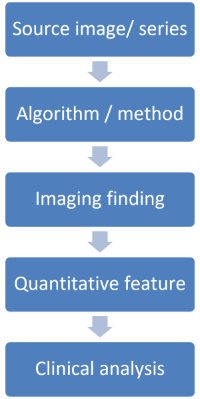

**Concepts used in the next cell**

*OMOP standard concepts*

| concept_id | Name | Domain | Vocabulary | Class | Code |
|---|---|---|---|---|---|
| [1147330](https://athena.ohdsi.org/search-terms/terms/1147330) | measurement | Metadata | CDM | Table | CDM386 |
| [4319884](https://athena.ohdsi.org/search-terms/terms/4319884) | Consolidation | Observation | SNOMED | Morph Abnormality | 9656002 |
| [4163872](https://athena.ohdsi.org/search-terms/terms/4163872) | Plain X-ray of chest | Procedure | SNOMED | Procedure | 399208008 |

*Custom concepts* (section 11)

| concept_id | Name |
|---|---|
| 2128500003 | Consolidation score, TorchXRayVision DenseNet121 |

,0
measurement_id,2165
feature,"Consolidation score, TorchXRayVision DenseNet121"
value,0.652227
finding,Consolidation
image_occurrence_id,45
image_series_uid,1.2.276.0.7230010.3.1.3.8323329.10044.1517874346.509901
local_path,/content/micdm_tutorial/dicom/mdai_rsna_project_x9N20BZa...
procedure_occurrence_id,45
procedure,Plain X-ray of chest
alg_system,TorchXRayVision DenseNet121 [densenet121-res224-all] tor...


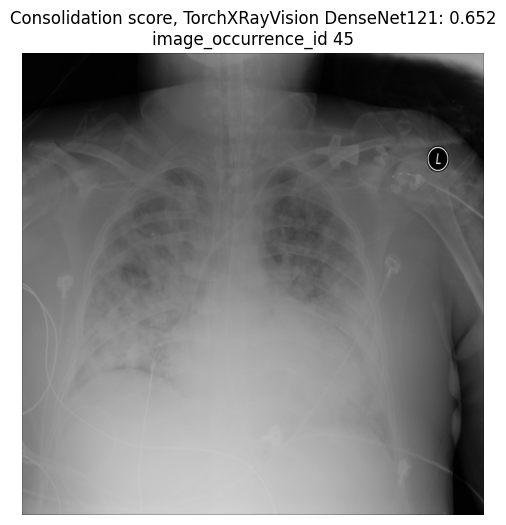

In [42]:
# Trace the history of the highest Consolidation score
trace = q("""
SELECT m.measurement_id, mc.concept_name AS feature, m.value_as_number AS value, fc.concept_name AS finding,
       io.image_occurrence_id, io.image_series_uid, io.local_path,
       po.procedure_occurrence_id, pc.concept_name AS procedure,
       f.alg_system, f.alg_datetime,
       r.weights_sha256, r.preprocessing, r.hyperparameters
FROM measurement m
JOIN image_feature f         ON f.image_feature_event_id = m.measurement_id AND f.image_feature_event_field_concept_id = 1147330
JOIN image_occurrence io     ON io.image_occurrence_id = m.measurement_event_id
JOIN procedure_occurrence po ON po.procedure_occurrence_id = io.procedure_occurrence_id
LEFT JOIN concept mc         ON mc.concept_id = m.measurement_concept_id
LEFT JOIN concept pc         ON pc.concept_id = po.procedure_concept_id
LEFT JOIN concept fc         ON fc.concept_id = f.image_finding_concept_id
LEFT JOIN local_model_run r  ON r.alg_system = f.alg_system
WHERE m.measurement_concept_id = 2128500003          -- Consolidation score (custom)
  AND m.value_as_number IS NOT NULL
ORDER BY m.value_as_number DESC LIMIT 1
""")
display(trace.T)

# display the image of this image_occurrence_id (IMAGE_OCCURRENCE.local_path)
import pydicom
import matplotlib.pyplot as plt
from pydicom.pixel_data_handlers.util import apply_voi_lut

row = trace.iloc[0]
ds = pydicom.dcmread(row.local_path)
img = apply_voi_lut(ds.pixel_array, ds)
if ds.get("PhotometricInterpretation") == "MONOCHROME1":
    img = img.max() - img
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title(f"{row.feature}: {row.value:.3f}\nimage_occurrence_id {row.image_occurrence_id}")
plt.axis("off")
plt.show()

### From the values back to the images

**Concepts used in the next cell**

*OMOP standard concepts*

| concept_id | Name | Domain | Vocabulary | Class | Code |
|---|---|---|---|---|---|
| [32817](https://athena.ohdsi.org/search-terms/terms/32817) | EHR | Type Concept | Type Concept | Type Concept | OMOP4976890 |
| [44807121](https://athena.ohdsi.org/search-terms/terms/44807121) | Cardiothoracic ratio | Measurement | SNOMED | Observable Entity | 815571000000107 |

*Custom concepts* (2-billion range, non-standard)

| Tag | Attribute | Custom concept_id | Source |
|---|---|---|---|
| (0010,0040) | Patient's Sex | 2128000288 | [staging v5](https://github.com/paulnagy/DICOM2OMOP/blob/56be2b80c9ba2c9b8f19dc36a8ab5919aed6fb88/files/OMOP%20CDM%20Staging/omop_table_staging_v5.csv) — DICOM Attributes |
| (0018,5101) | View Position | 2128001098 | staging v5 — DICOM Attributes |
| (0018,5100) | Patient Position | 2128001097 | staging v5 — DICOM Attributes |
| (0008,0070) | Manufacturer | 2128000056 | staging v5 — DICOM Attributes |
| (0028,0010) | Rows | 2128002092 | staging v5 — DICOM Attributes |
| (0028,0011) | Columns | 2128002093 | staging v5 — DICOM Attributes |
| (0028,0030) | Pixel Spacing | 2128002096 | staging v5 — DICOM Attributes |
| (0018,1164) | Imager Pixel Spacing | 2128000944 | staging v5 — DICOM Attributes |
| (0028,0004) | Photometric Interpretation | 2128002086 | staging v5 — DICOM Attributes |
| (0018,0060) | KVP | 2128000818 | staging v5 — DICOM Attributes |
| (0018,1152) | Exposure | 2128000934 | staging v5 — DICOM Attributes |
| (0018,1151) | X-Ray Tube Current | 2128000933 | staging v5 — DICOM Attributes |
| (0018,1150) | Exposure Time | 2128000932 | staging v5 — DICOM Attributes |
| (0018,1110) | Distance Source to Detector | 2128000910 | staging v5 — DICOM Attributes |
| — | Consolidation score, TorchXRayVision DenseNet121 | 2128500003 | section 11 |

In [43]:
# Define the function that compares the lowest and the highest value of one feature
import pydicom
import matplotlib.pyplot as plt
from pydicom.pixel_data_handlers.util import apply_voi_lut


def show_images(paths, titles):
    """Display DICOM images side by side (window/LUT applied, MONOCHROME1 inverted)."""
    fig, axes = plt.subplots(1, len(paths), figsize=(6 * len(paths), 6))
    for ax, path, title in zip(np.atleast_1d(axes), paths, titles):
        ds = pydicom.dcmread(path)
        img = apply_voi_lut(ds.pixel_array, ds)
        if ds.get("PhotometricInterpretation") == "MONOCHROME1":
            img = img.max() - img
        ax.imshow(img, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# DICOM attributes to compare (tag -> name): patient, view, image geometry, acquisition
COMPARE_TAGS = {
    "00100040": "Patient's Sex",
    "00185101": "View Position",
    "00185100": "Patient Position",
    "00080070": "Manufacturer",
    "00280010": "Rows",
    "00280011": "Columns",
    "00280030": "Pixel Spacing",
    "00181164": "Imager Pixel Spacing",
    "00280004": "Photometric Interpretation",
    "00180060": "KVP",
    "00181152": "Exposure",
    "00181151": "X-Ray Tube Current",
    "00181150": "Exposure Time",
    "00181110": "Distance Source to Detector",
}


def compare_extremes(measurement_concept_id):
    """Lowest vs highest value of one feature: images and the DICOM attributes that differ."""
    # 1. the feature values and their images (MEASUREMENT -> IMAGE_OCCURRENCE)
    values_all = q("""
        SELECT m.value_as_number AS value, io.image_occurrence_id, io.local_path, c.concept_name AS feature
        FROM measurement m
        JOIN image_occurrence io ON io.image_occurrence_id = m.measurement_event_id
        JOIN concept c           ON c.concept_id = m.measurement_concept_id
        WHERE m.measurement_concept_id = ? AND m.value_as_number IS NOT NULL
        ORDER BY m.value_as_number""", (measurement_concept_id,))
    lo, hi = values_all.iloc[0], values_all.iloc[-1]
    # 2. the two images
    show_images([lo.local_path, hi.local_path],
                [f"lowest: {lo.value:.3f} (image_occurrence_id {lo.image_occurrence_id})",
                 f"highest: {hi.value:.3f} (image_occurrence_id {hi.image_occurrence_id})"])
    # 3. the DICOM header attributes of the same two images (MEASUREMENT, type 32817)
    dicom = q("""
        SELECT m.measurement_event_id AS image_occurrence_id, c.concept_code AS tag, m.value_source_value AS value
        FROM measurement m
        JOIN concept c ON c.concept_id = m.measurement_concept_id
        WHERE m.measurement_type_concept_id = 32817 AND m.measurement_event_id IN (?, ?)""",
        (int(lo.image_occurrence_id), int(hi.image_occurrence_id)))
    values = dicom.groupby(["tag", "image_occurrence_id"])["value"].agg(", ".join).unstack()
    table = pd.DataFrame({"attribute": list(COMPARE_TAGS.values())}, index=list(COMPARE_TAGS))
    for col, img in [("lowest", lo.image_occurrence_id), ("highest", hi.image_occurrence_id)]:
        table[f"{col} (id {img})"] = values[img].reindex(table.index).fillna("(not in header)") if img in values else "(not in header)"
    table["differs"] = table.iloc[:, 1] != table.iloc[:, 2]
    print(f"{lo.feature}: {len(values_all)} images. Attributes that differ: {int(table['differs'].sum())} of {len(table)}.")
    return table.reset_index(names="tag")

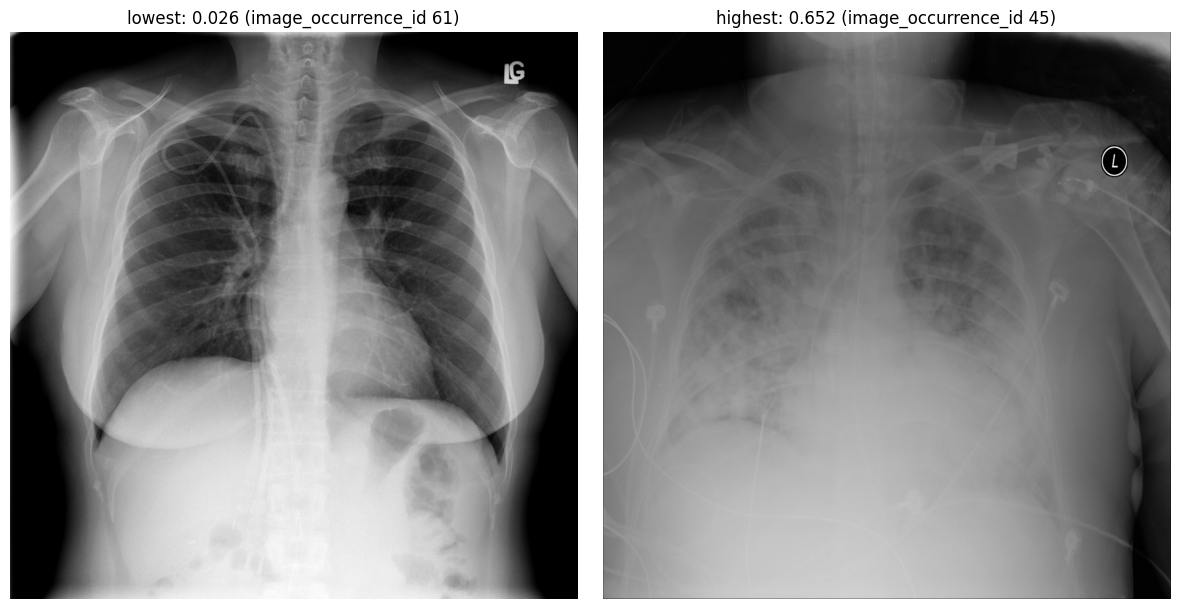

Consolidation score, TorchXRayVision DenseNet121: 100 images. Attributes that differ: 3 of 14.


,tag,attribute,lowest (id 61),highest (id 45),differs
0,00100040,Patient's Sex,F,M,True
1,00185101,View Position,PA,AP,True
2,00185100,Patient Position,(not in header),(not in header),False
3,00080070,Manufacturer,(not in header),(not in header),False
4,00280010,Rows,1024,1024,False
5,00280011,Columns,1024,1024,False
6,00280030,Pixel Spacing,"0.14300000000000002, 0.14300000000000002","0.168, 0.168",True
7,00181164,Imager Pixel Spacing,(not in header),(not in header),False
8,00280004,Photometric Interpretation,MONOCHROME2,MONOCHROME2,False
9,00180060,KVP,(not in header),(not in header),False


In [44]:
# Compare the images with the lowest and the highest Consolidation score
compare_extremes(2128500003)          # Consolidation score, TorchXRayVision DenseNet121 (custom)

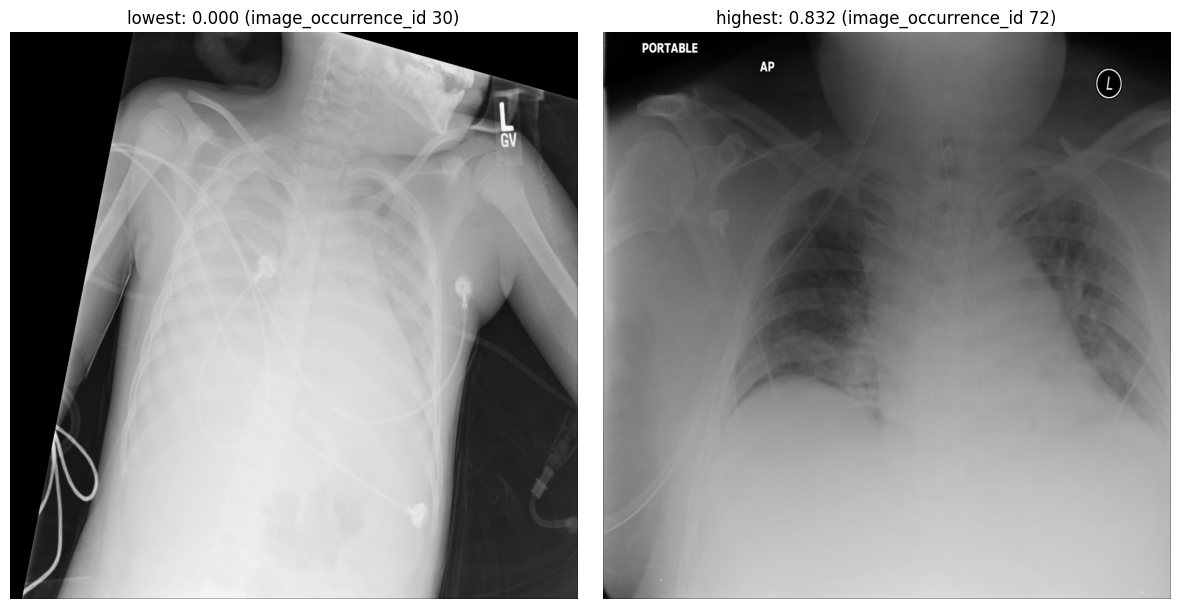

Cardiothoracic ratio: 99 images. Attributes that differ: 1 of 14.


,tag,attribute,lowest (id 30),highest (id 72),differs
0,00100040,Patient's Sex,F,M,True
1,00185101,View Position,AP,AP,False
2,00185100,Patient Position,(not in header),(not in header),False
3,00080070,Manufacturer,(not in header),(not in header),False
4,00280010,Rows,1024,1024,False
5,00280011,Columns,1024,1024,False
6,00280030,Pixel Spacing,"0.168, 0.168","0.168, 0.168",False
7,00181164,Imager Pixel Spacing,(not in header),(not in header),False
8,00280004,Photometric Interpretation,MONOCHROME2,MONOCHROME2,False
9,00180060,KVP,(not in header),(not in header),False


In [45]:
# Compare the images with the smallest and the largest cardiothoracic ratio
compare_extremes(44807121)            # Cardiothoracic ratio (SNOMED, standard)

### Your turn — trace another feature

The next cell runs the same query. Only the `measurement_concept_id` is open: fill in `MY_MEASUREMENT_CONCEPT_ID` with one of the candidates listed in the cell, then run it.

In [46]:
# Trace the history of the highest value of a feature you choose
#   Fill in one measurement_concept_id, then run this cell. Candidates:
#   2128500001  Lung opacity score                (classification, custom)
#   2128500002  Enlarged cardiomediastinum score  (classification, custom)
#   2128500003  Consolidation score               (classification, custom)
#   44807121    Cardiothoracic ratio              (segmentation, SNOMED standard)
#   2128500101  Cardiac transverse diameter, mm   (segmentation, custom)
#   2128500102  Lung field transverse width, mm   (segmentation, custom)
MY_MEASUREMENT_CONCEPT_ID = None        # e.g. 44807121

if MY_MEASUREMENT_CONCEPT_ID is None:
    print("Set MY_MEASUREMENT_CONCEPT_ID (see the candidates above), then run this cell again.")
else:
    display(q("""
SELECT m.measurement_id, mc.concept_name AS feature, m.value_as_number AS value, fc.concept_name AS finding,
       io.image_occurrence_id, io.image_series_uid, io.local_path,
       po.procedure_occurrence_id, pc.concept_name AS procedure,
       f.alg_system, f.alg_datetime,
       r.weights_sha256, r.preprocessing, r.hyperparameters
FROM measurement m
JOIN image_feature f         ON f.image_feature_event_id = m.measurement_id AND f.image_feature_event_field_concept_id = 1147330
JOIN image_occurrence io     ON io.image_occurrence_id = m.measurement_event_id
JOIN procedure_occurrence po ON po.procedure_occurrence_id = io.procedure_occurrence_id
LEFT JOIN concept mc         ON mc.concept_id = m.measurement_concept_id
LEFT JOIN concept pc         ON pc.concept_id = po.procedure_concept_id
LEFT JOIN concept fc         ON fc.concept_id = f.image_finding_concept_id
LEFT JOIN local_model_run r  ON r.alg_system = f.alg_system
WHERE m.measurement_concept_id = ?
  AND m.value_as_number IS NOT NULL
ORDER BY m.value_as_number DESC LIMIT 1
""", (MY_MEASUREMENT_CONCEPT_ID,)).T)

Set MY_MEASUREMENT_CONCEPT_ID (see the candidates above), then run this cell again.


## Data quality for derived features

**Concepts used in the next cell**

*Standard / OMOP-defined concepts* (verified 2026-09-29; links open Athena)

| concept_id | Name | Domain | Vocabulary | Class | Code |
|---|---|---|---|---|---|
| [0](https://athena.ohdsi.org/search-terms/terms/0) | No matching concept | Metadata | None | Undefined | No matching concept |
| [1147330](https://athena.ohdsi.org/search-terms/terms/1147330) | measurement | Metadata | CDM | Table | CDM386 |
| [32880](https://athena.ohdsi.org/search-terms/terms/32880) | Standard algorithm | Type Concept | Type Concept | Type Concept | OMOP4976953 |
| [44807121](https://athena.ohdsi.org/search-terms/terms/44807121) | Cardiothoracic ratio | Measurement | SNOMED | Observable Entity | 815571000000107 |

In [47]:
# Run the data quality checks of notebooks 01 and 02
DQ_CHECKS_PART2 = [
    ("linkage", "image_feature -> image_occurrence unresolved",
     "SELECT COUNT(*) FROM image_feature f LEFT JOIN image_occurrence io USING (image_occurrence_id) WHERE io.image_occurrence_id IS NULL"),
    ("linkage", "image_feature -> measurement unresolved",
     """SELECT COUNT(*) FROM image_feature f LEFT JOIN measurement m ON m.measurement_id = f.image_feature_event_id
        WHERE f.image_feature_event_field_concept_id = 1147330 AND m.measurement_id IS NULL"""),
    ("linkage", "feature and its measurement point at different images",
     """SELECT COUNT(*) FROM image_feature f JOIN measurement m ON m.measurement_id = f.image_feature_event_id
        WHERE f.image_feature_event_field_concept_id = 1147330 AND m.measurement_event_id <> f.image_occurrence_id"""),
    ("linkage", "feature person differs from image person",
     "SELECT COUNT(*) FROM image_feature f JOIN image_occurrence io USING (image_occurrence_id) WHERE f.person_id <> io.person_id"),
    ("completeness", "algorithm feature without alg_system / alg_datetime",
     "SELECT COUNT(*) FROM image_feature WHERE image_feature_type_concept_id = 32880 AND (alg_system IS NULL OR alg_datetime IS NULL)"),
    ("completeness", "alg_system not traceable to local_model_run",
     "SELECT COUNT(*) FROM image_feature f LEFT JOIN local_model_run r USING (alg_system) WHERE f.image_feature_type_concept_id = 32880 AND r.model_run_id IS NULL"),
    ("completeness", "model run without weight checksum",
     "SELECT COUNT(*) FROM local_model_run WHERE weights_sha256 IS NULL"),
    ("conformance", "finding concept_id = 0 (no standard finding concept)",
     "SELECT COUNT(*) FROM image_feature WHERE image_finding_concept_id = 0"),
    ("plausibility", "classifier score outside [0, 1]",
     """SELECT COUNT(*) FROM measurement WHERE measurement_type_concept_id = 32880
        AND measurement_source_value LIKE '% score' AND (value_as_number < 0 OR value_as_number > 1)"""),
]
# ▶ run
run_dq(DQ_CHECKS_PART1 + DQ_CHECKS_PART2)

,category,check,violations,status
0,completeness,image_occurrence without person / procedure,0,PASS
1,completeness,image_occurrence missing study/series UID or date,0,PASS
2,completeness,image_occurrence with modality_concept_id = 0,0,PASS
3,completeness,image_occurrence without wadors_uri AND local_path,0,PASS
4,completeness,DICOM measurement without measurement_event_id,0,PASS
5,conformance,concept_ids not present in CONCEPT (image_occurrence),0,PASS
6,conformance,measurement_concept_id not a DICOM attribute (DICOM rows),0,PASS
7,conformance,measurement without source value,0,PASS
8,conformance,CS value stored as number / numeric VR stored as concept,0,PASS
9,conformance,"duplicate (study_uid, series_uid)",0,PASS


## Summary

| Table | New rows | Holds |
|---|---|---|
| `image_feature` (type 32880) | 6 per image (3 classifier + 3 segmentation) | what/where/which algorithm |
| `measurement` (type 32880) | same count | the values (DICOM header rows from notebook 01 are type 32817) |
| `local_model_run` (site-local) | 1 per model run | full recipe |

The download in the next cell holds the OMOP CDM and MI-CDM tables, the vocabulary subset and `local_model_run`. The ETL work tables of notebook 01 (`stg_dicom_inventory`, `stg_dicom_metadata_long`, `registry_idmap`, `stg_study_procedure`) are left out.

In [48]:
# Export the OMOP CDM and MI-CDM tables and download the database
import sqlite3

STAGING_TABLES = ["stg_dicom_inventory", "stg_dicom_metadata_long", "registry_idmap", "stg_study_procedure"]
EXPORT_PATH = os.path.join(os.path.dirname(DB_PATH), "export", "omop_micdm.db")
os.makedirs(os.path.dirname(EXPORT_PATH), exist_ok=True)
if os.path.exists(EXPORT_PATH):
    os.remove(EXPORT_PATH)

src = sqlite3.connect(DB_PATH)
dst = sqlite3.connect(EXPORT_PATH, isolation_level=None)
src.backup(dst)                                  # copy the working database
src.close()
for t in STAGING_TABLES:                         # remove the ETL work tables (not OMOP / MI-CDM)
    dst.execute(f"DROP TABLE IF EXISTS {t}")
dst.execute("VACUUM")
tables = [r[0] for r in dst.execute("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")]
counts = [(t, dst.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]) for t in tables]
dst.close()
print(pd.DataFrame(counts, columns=["table", "rows"]).to_string(index=False))
print(f"\n{os.path.getsize(EXPORT_PATH) / 1e6:.1f} MB:", EXPORT_PATH)

try:
    from google.colab import files
    files.download(EXPORT_PATH)
except ImportError:
    print("Not on Colab — database is at", EXPORT_PATH)

               table  rows
             concept  8830
concept_relationship  1052
       image_feature   599
    image_occurrence   100
     local_model_run     2
         measurement  2499
  observation_period   100
              person   100
procedure_occurrence   100

1.5 MB: /content/micdm_tutorial/export/omop_micdm.db


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## View the database in your browser

1. Open **SQLite Viewer**: [https://sqliteviewer.app/](https://sqliteviewer.app/)
2. Drop the downloaded `omop_micdm.db` onto the page, or click the page and choose the file. You downloaded a file with the same name in notebook 01, so the browser probably saved this one as **`omop_micdm (2).db`**. Use that file.